# One KBM, many numerics: SPR-045 `kbm_free` sample_0818 against WIDTH and NBASIS (GFTM pointwise, GFTM Galerkin, TGLF)

Fusion_PhD-qp5.26. The single-mode version of the Latin-hypercube figures of `gftm_galerkin_field_width_selection.ipynb`
(qp5.24) and `gftm_quadrature_extent.ipynb` / `tglf_quadrature_extent.ipynb`: how the growth rate, frequency and
eigenfunction of one well-resolved GS2 KBM depend on the Hermite basis WIDTH $W$ and size $N$ (NBASIS).

**The mode.** SPR-045 `kbm_free` GS2 `sample_0818` (user's pick, 2026-11-01): $k_y\rho = 0.0198$, free parity, a clean KBM
under the user classifier ($T < 0.05$, $\omega > 0$, $0.25 < \chi_e/\chi_i < 4$; values printed below).

**Runs** (Fusion_PhD `results/spr045_single_kbm/`, GyroRun YAMLs): one leaf per arm under
`<CODE>/Runs/single_mode_spr045/SPR-045/`, each a cube of copies of this one GS2 deck in which only WIDTH / NBASIS
(/ NXGRID) change from run to run; the settings of every run are per-sample variables of its `pyroscan.nc`.
- GFTM `galF` (pointwise field solve, production) and `galT` (Galerkin, `FIELD_GALERKIN T`), both on the Galerkin build:
  NBASIS 2/4/8/16/32 at NXGRID 32 and 64 at NXGRID 65; FILTER 0.5, IBRANCH $-1$, NMODES 4 (as qp5.24).
- TGLF `fixed_width`: NBASIS_MAX 2/4/8/16/32, NXGRID 32, FILTER 0, THETA_TRAPPED 0.7, FIND_WIDTH F (as tglf_quadrature_extent).
- TGLF `find_width`: FIND_WIDTH T over 0.2–4.0, NBASIS_MIN 2/4/8/16/32, NBASIS_MAX 32 (as tglf_find_width part B).
- 47 widths: the 24-point `WIDTH_ORACLE_GRID` (0.2–4.0) and its geometric midpoints.

**Conventions.** Dominant mode = $\arg\max$ of the growth rate over `mode`; a run with no unstable mode has $\gamma = 0$.
pyro's $\omega > 0$ is the ion direction, for every code. Extent = pyro `Extent`, the $\theta$ range holding 95% of
$|\cdot|^2$; extent ratio = code / GS2. $B_\parallel$ is read with pyro PR #613 (`e2772bd`, not merged; re-saved
`pyroscan.nc` per leaf), because GyroRun's pinned pyro stores GFTM's raw $\sigma = \delta B_\parallel/(B k_\perp\rho)$;
`Fusion_PhD-38e9.30` (`results/gftm_bpar_extent`) shows the pointwise GFTM $B_\parallel$ extent fails at large $W$ for
numerical reasons that the Galerkin solve removes. GS2 holds $|\phi|^2$ only, so eigenfunctions are compared in modulus.

Advisory (agent analysis).

In [1]:
from pathlib import Path
import os
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter
import pyrokinetics
from pyrokinetics import PyroHypercube
from pyrokinetics.diagnostics.extent import Extent

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir()
)
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
# slide-ready text (user, 2026-11-01: >= 16 pt)
plt.rcParams.update({"font.size": 16, "axes.labelsize": 18, "axes.titlesize": 18, "xtick.labelsize": 16, "ytick.labelsize": 16})
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
print("pyrokinetics", pyrokinetics.__version__)

analysis_name = "spr045_single_kbm"
sample = "sample_0818"
gs2_leaf = Path(os.environ["GK_DATA_ROOT"]).expanduser() / "GS2" / "Runs" / "LATIN_HYPERCUBE" / "SPR-045" / "kbm_free"
# GyroRun wrote this scan to the scratch tree
single_root = Path(os.environ["GYRO_DATA_OUTPUT"])
leaves = {"F": single_root / "GFTM/Runs/single_mode_spr045/SPR-045/galF_sample_0818",
          "T": single_root / "GFTM/Runs/single_mode_spr045/SPR-045/galT_sample_0818",
          "TGLF": single_root / "TGLF/Runs/single_mode_spr045/SPR-045/fixed_width_sample_0818"}
find_width_leaf = single_root / "TGLF/Runs/single_mode_spr045/SPR-045/find_width_sample_0818"
# the same leaves re-saved with the pyro #613 B_par reader (rebuild_bpar.py in Fusion_PhD results/spr045_single_kbm)
bpar_leaves = {arm: leaf.parent / "bpar613" / leaf.name for arm, leaf in leaves.items()}
arms = {"F": "GFTM pointwise", "T": "GFTM Galerkin", "TGLF": "TGLF"}
arm_colours = {"F": "C0", "T": "C3", "TGLF": "C2"}
nbasis_all = [2, 4, 8, 16, 32, 64]
fields = ["phi", "apar", "bpar"]
field_labels = {"phi": r"$\phi$", "apar": r"$A_\parallel$", "bpar": r"$B_\parallel$"}
fraction = 0.95                         # pyro Extent: theta range holding 95% of |field|^2
overshoot_tolerance = 0.10
fs_title, fs_legend = 18, 16


def log_xticks(ax, ticks):
    lims = ax.get_xlim()
    ax.set_xticks(ticks)
    ax.set_xlim(lims)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()

pyrokinetics 0.9.2.dev153+g3290c692


## GS2 reference: is sample_0818 a clean KBM?

The `kbm_free` cube, this sample only. Classifier quantities as in `docs/mode_filtering.md`: tearing parameter $T$
(saved by the cube), $\omega$ sign, and $\chi_e/\chi_i$ from the cube's heat and particle fluxes (the candidate script
`results/spr045_single_kbm/candidate_eigenfunctions.py` computed the same; its kbm_free species rule is repeated here).

In [2]:
gs2_scan = PyroHypercube(pyroscan_json=gs2_leaf / "pyroscan.json", load_base_pyro=True)
gs2_scan.load_gk_output(netcdf_file=gs2_leaf / "pyroscan.nc")
sample_index = list(gs2_scan.gk_output.data.sample_name.values.astype(str)).index(sample)
gs2_output = gs2_scan.gk_output.data.isel(sample=sample_index).pint.dequantify()

species = gs2_scan.sample_pyro(sample_index).local_species
ions = [name for name in species.names if name != "electron"]
# the kbm_free deck rule (docs/gyro_data_runs.md): ions share the first ion's a/L_T, every a/L_n is the electron's
for ion in ions:
    species[ion].inverse_ln = species.electron.inverse_ln
    species[ion].inverse_lt = species[ions[0]].inverse_lt
heat, particle = gs2_output.heat.sum("field"), gs2_output.particle.sum("field")
chi = lambda group: (sum(float(heat.sel(species=s)) - 1.5 * species[s].temp.m * float(particle.sel(species=s)) for s in group)
                     / sum(species[s].dens.m * species[s].temp.m * species[s].inverse_lt.m for s in group))

gamma_gs2, omega_gs2 = float(gs2_output.growth_rate), float(gs2_output.mode_frequency)
gs2_power = {field: gs2_output.eigenfunctions_squared.sel(field=field).isel(kx=0).dropna("theta") for field in fields}
extent_gs2 = {field: float(Extent._compute(power, fraction)[0]) for field, power in gs2_power.items()}
print(f"ky {float(gs2_output.ky):.4f} | gamma {gamma_gs2:.4f} | omega {omega_gs2:+.4f} | T {float(gs2_output.tearing_parameter):.1e} "
      f"| chi_e/chi_i {chi(['electron']) / chi(ions):.2f} | growth_rate_tolerance {float(gs2_output.growth_rate_tolerance):.1e} "
      f"| phi even fraction {float(gs2_output.phi_even_fraction):.3f}, apar {float(gs2_output.apar_even_fraction):.3f}")
theta_box = float(gs2_power["phi"].theta.max())
print("extent (rad):", {field: round(value, 3) for field, value in extent_gs2.items()}, "| theta box +-", round(theta_box, 2))
print("|phi| at the box edge / max:", float(np.sqrt(gs2_power["phi"][[0, -1]].max() / gs2_power["phi"].max())))

ky 0.0198 | gamma 1.3708 | omega +0.1760 | T 1.1e-11 | chi_e/chi_i 1.10 | growth_rate_tolerance 5.7e-05 | phi even fraction 1.000, apar 0.000
extent (rad): {'phi': 1.638, 'apar': 2.258, 'bpar': 1.549} | theta box +- 15.71
|phi| at the box edge / max: 9.375572006480374e-06


## Case slide: the mode and how it differs from the SPR-045 base deck

GS2 $|\phi|(\theta)$ and $|A_\parallel|(\theta)$ of sample_0818, normalised to their maxima, and the 8 sampled cube parameters
of sample_0818 against the base deck (the cube's `base_pyro`, i.e. `Templates/SPR-045/gs2_lhc.in`), both in pyro units.

                          base  sample_0818
ky                      0.0199       0.0198
q                       3.7883       2.5902
shat                    4.6401       4.6827
beta                    0.0552       0.0303
ion_temp_gradient       5.7620       6.9954
electron_temp_gradient  2.4367       2.6032
electron_dens_gradient  4.9812       3.3614
electron_nu             0.0347       0.0060


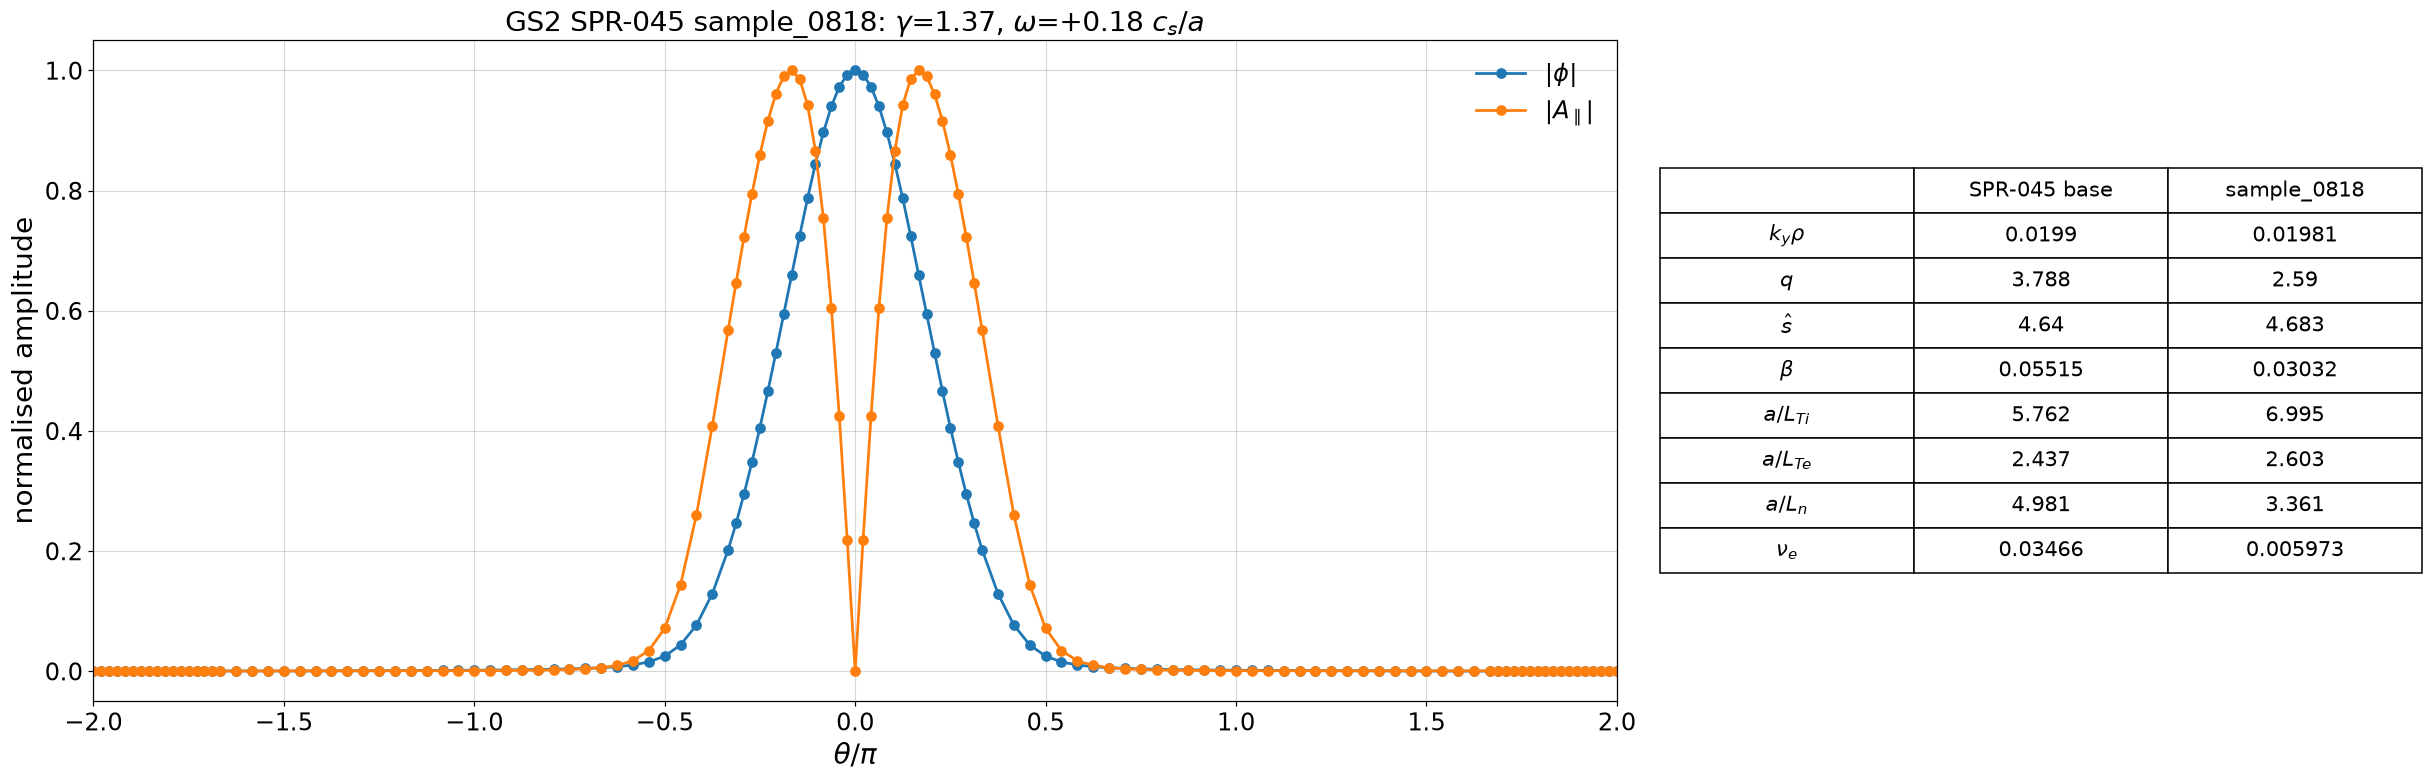

In [3]:
base = gs2_scan.base_pyro
base_species = base.local_species
base_values = dict(ky=base.numerics.ky.to(base.norms.pyrokinetics).m, q=base.local_geometry.q, shat=base.local_geometry.shat,
                   beta=base.numerics.beta.to(base.norms.pyrokinetics).m, ion_temp_gradient=base_species[base_species.names[0]].inverse_lt.m,
                   electron_temp_gradient=base_species.electron.inverse_lt.m, electron_dens_gradient=base_species.electron.inverse_ln.m,
                   electron_nu=base_species.electron.nu.to(base.norms.pyrokinetics).m)
parameter_labels = dict(ky=r"$k_y\rho$", q="$q$", shat=r"$\hat s$", beta=r"$\beta$", ion_temp_gradient="$a/L_{Ti}$",
                        electron_temp_gradient="$a/L_{Te}$", electron_dens_gradient="$a/L_n$", electron_nu=r"$\nu_e$")
parameters = pd.DataFrame({"base": {name: float(value) for name, value in base_values.items()}, sample: {name: float(gs2_output[name]) for name in base_values}})
print(parameters.round(4).to_string())

fig0, axes0 = plt.subplots(1, 2, figsize=(22, 7), gridspec_kw={"width_ratios": [2, 1]})
for field, colour in (("phi", "C0"), ("apar", "C1")):
    amplitude = np.sqrt(gs2_power[field] / gs2_power[field].max())
    axes0[0].plot(amplitude.theta / np.pi, amplitude, color=colour, label=f"|{field_labels[field]}|")
axes0[0].set(xlabel=r"$\theta/\pi$", ylabel="normalised amplitude", xlim=(-2, 2))
axes0[0].set_title(rf"GS2 SPR-045 {sample}: $\gamma$={gamma_gs2:.2f}, $\omega$={omega_gs2:+.2f} $c_s/a$", fontsize=fs_title)
axes0[0].legend(fontsize=fs_legend)
axes0[1].axis("off")
cells = [[parameter_labels[name], f"{parameters.base[name]:.4g}", f"{parameters[sample][name]:.4g}"] for name in base_values]
table_artist = axes0[1].table(cellText=cells, colLabels=["", "SPR-045 base", sample], loc="center", cellLoc="center")
table_artist.set_fontsize(16)
table_artist.scale(1, 2.2)
plt.show()

## GFTM and TGLF leaves

One `PyroHypercube` per leaf. Each run's WIDTH and NBASIS_MAX are per-sample variables of the cube (GyroRun
`code_flags_per_sample`); the audit of `input.*.gen` (requested) against `out.*.localdump` / `out.tglf.globaldump`
(used) is in the Fusion_PhD README.

In [4]:
outputs, bpar_outputs = {}, {}
for arm, leaf in leaves.items():
    scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    Extent(scan.gk_output, fraction=fraction)
    outputs[arm] = scan.gk_output.data.pint.dequantify().squeeze("ky", drop=True)   # one ky per run
    bpar_scan = PyroHypercube(pyroscan_json=bpar_leaves[arm] / "pyroscan.json", load_base_pyro=True)
    bpar_scan.load_gk_output(netcdf_file=bpar_leaves[arm] / "pyroscan.nc")
    Extent(bpar_scan.gk_output, fraction=fraction)
    bpar_outputs[arm] = bpar_scan.gk_output.data.pint.dequantify().squeeze("ky", drop=True)   # one ky per run

rows = []
for arm, output in outputs.items():
    dominant_index = output.growth_rate.fillna(-np.inf).argmax("mode")
    dominant = output.isel(mode=dominant_index)
    bpar_extent = bpar_outputs[arm].extent.sel(field="bpar").isel(mode=dominant_index)
    gamma = dominant.growth_rate.clip(min=0).fillna(0).values
    unstable = gamma > 0
    rows.append(pd.DataFrame(dict(
        arm=arm, W=np.round(output.WIDTH.values.astype(float), 4), nb=output.NBASIS_MAX.values.astype(int), gamma=gamma,
        omega=np.where(unstable, dominant.mode_frequency.values, np.nan),
        **{f"extent_{field}": np.where(unstable, dominant.extent.sel(field=field).values, np.nan) for field in ["phi", "apar"]},
        extent_bpar=np.where(unstable, bpar_extent.values, np.nan), sample_index=np.arange(output.sizes["sample"]))))
table = pd.concat(rows, ignore_index=True).sort_values(["arm", "nb", "W"])
for field in fields:
    table[f"log_extent_ratio_{field}"] = np.log10(table[f"extent_{field}"] / extent_gs2[field])
widths = np.sort(table.W.unique())
print(table.groupby(["arm", "nb"]).size().unstack(), "\nwidths:", len(widths), widths.min(), "-", widths.max())
print("runs with no unstable mode:", table[table.gamma == 0].groupby(["arm", "nb"]).size().to_dict())

find_scan = PyroHypercube(pyroscan_json=find_width_leaf / "pyroscan.json", load_base_pyro=True)
find_scan.load_gk_output(netcdf_file=find_width_leaf / "pyroscan.nc")
find_output = find_scan.gk_output.data.pint.dequantify().squeeze("ky", drop=True)   # one ky per run
find_dominant = find_output.isel(mode=find_output.growth_rate.fillna(-np.inf).argmax("mode"))
# gaussian_width (pyro #616): the width TGLF's own search chose
find_width = pd.DataFrame(dict(nb_min=find_output.NBASIS_MIN.values.astype(int), W=find_dominant.gaussian_width.values,
                               gamma=find_dominant.growth_rate.values, omega=find_dominant.mode_frequency.values))
print("TGLF FIND_WIDTH T:\n", find_width.round(4).to_string(index=False))

nb      2     4     8     16    32    64
arm                                     
F     47.0  47.0  47.0  47.0  47.0  47.0
T     47.0  47.0  47.0  47.0  47.0  47.0
TGLF  47.0  47.0  47.0  47.0  47.0   NaN 
widths: 47 0.2 - 4.0
runs with no unstable mode: {('T', 2): 1, ('TGLF', 2): 2}


TGLF FIND_WIDTH T:
  nb_min      W  gamma  omega
      2 0.3507 2.7266 0.0815
      4 0.2648 2.7288 0.0939
      8 0.2000 2.7288 0.0956
     16 0.3194 2.7299 0.0917
     32 0.2412 2.7305 0.0944


## 1. $\gamma(W)$ and $\omega(W)$ per NBASIS

Format copied from fig5 of `gftm_galerkin_field_width_selection.ipynb` (`axes5`: columns = NBASIS, log WIDTH axis,
one line per arm in the arm colours), with rows = $\gamma$, $\omega$ and the GS2 value as a black dashed line. Stars on
the TGLF curves: TGLF's own FIND_WIDTH choice with NBASIS_MIN = the column's NBASIS (final solve at NBASIS_MAX 32).

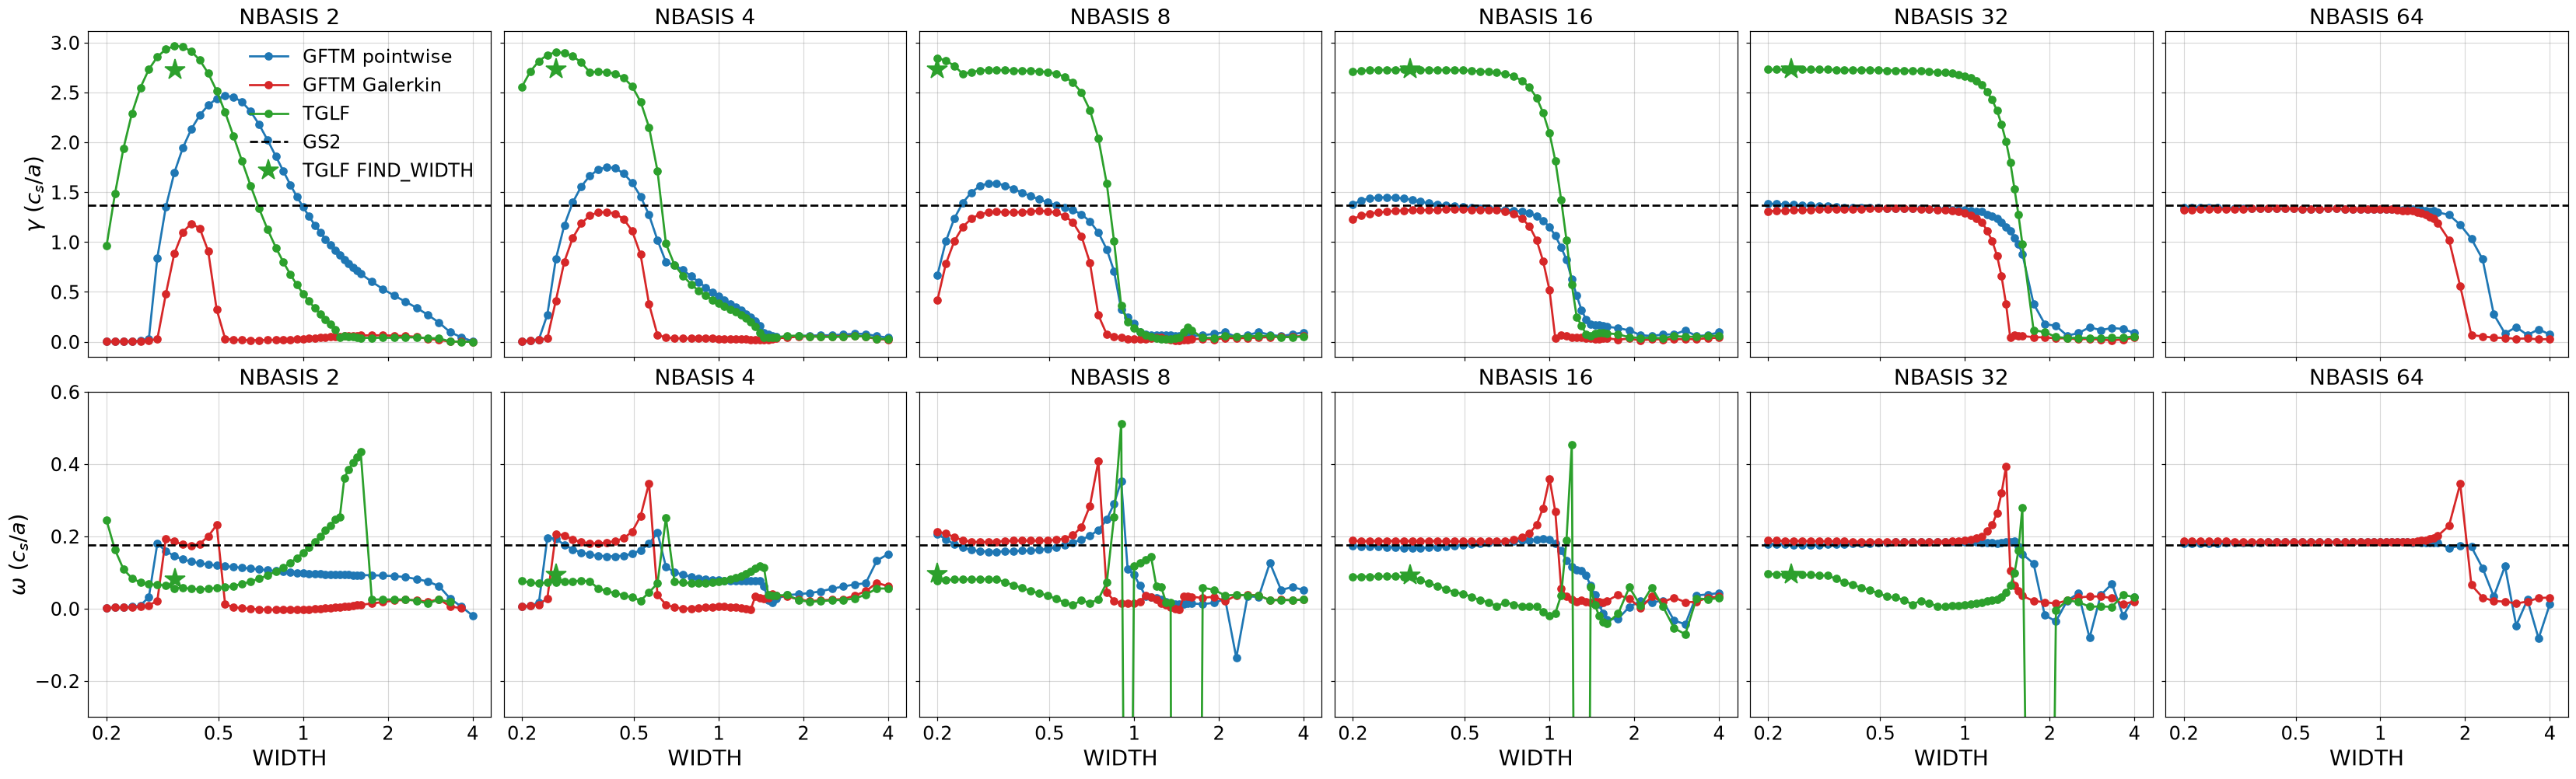

In [5]:
def per_nbasis(data, quantities, ylabels, reference=None, hline=None, figsize=(30, 9)):
    fig, axes = plt.subplots(len(quantities), len(nbasis_all), figsize=figsize, sharex=True, sharey="row", squeeze=False)
    for r, quantity in enumerate(quantities):
        for j, nb in enumerate(nbasis_all):
            ax = axes[r, j]
            for arm in arms:
                a = data[(data.arm == arm) & (data.nb == nb)]
                if len(a):
                    ax.plot(a.W, a[quantity], color=arm_colours[arm], label=arms[arm])
            if reference is not None:
                ax.axhline(reference[quantity], color="k", ls="--", marker="", label="GS2")
            if hline is not None:
                ax.axhline(hline, color="0.5", ls=":", marker="")
            ax.set(xscale="log")
            ax.set_title(f"NBASIS {nb}", fontsize=fs_title)
            if r == len(quantities) - 1:
                ax.set_xlabel("WIDTH")
                log_xticks(ax, [0.2, 0.5, 1, 2, 4])
        axes[r, 0].set_ylabel(ylabels[r])
    axes[0, 0].legend(fontsize=fs_legend)
    return fig, axes


fig1, axes1 = per_nbasis(table, ["gamma", "omega"], [r"$\gamma$ ($c_s/a$)", r"$\omega$ ($c_s/a$)"], reference={"gamma": gamma_gs2, "omega": omega_gs2})
for j, nb in enumerate(nbasis_all):
    for r, quantity in enumerate(["gamma", "omega"]):
        for _, row in find_width[find_width.nb_min == nb].iterrows():
            axes1[r, j].plot(row.W, row[quantity], ls="", marker="*", ms=18, color=arm_colours["TGLF"],
                             label="TGLF FIND_WIDTH" if (r, j) == (0, 0) else None)
axes1[1, 0].set_ylim(-0.3, 0.6)     # large-WIDTH runs that lost the KBM reach |omega| ~ 5
axes1[0, 0].legend(fontsize=fs_legend)
plt.show()

## 1b. The U: $\gamma_{\rm code}/\gamma_{\rm GS2}$ and $\omega_{\rm code}/\omega_{\rm GS2}$ against WIDTH, one line per NBASIS

Top TGLF, bottom GFTM (solid pointwise = stock, dashed Galerkin). Log $y$; runs with no unstable mode are left out.

**Theory overlay (thin grey, right axis, a SHAPE comparison only).** If the mode were a Gaussian of width $W^*$, its
representation error in an $N$-function Hermite basis of width $W = sW^*$ falls as $\varepsilon(N, s) \sim |r|^{N/2}$ with
$r = (s^2-1)/(s^2+1)$. $W^*$ is taken per code as the centre of the plateau of its largest NBASIS (TGLF 32, GFTM pointwise 64):
the grid width where $|\mathrm{d}\log\gamma/\mathrm{d}\log W|$ is smallest. The right axis is $\varepsilon$ itself on a log scale, so only the
widths at which each curve rises are comparable with the data, not their heights. A real mode that needs more basis
functions than a Gaussian shows a U that is narrower than the grey curve at the same $N$.

W* (theory overlay centre): {'TGLF': 0.5657, 'F': 0.2, 'T': 0.2462}


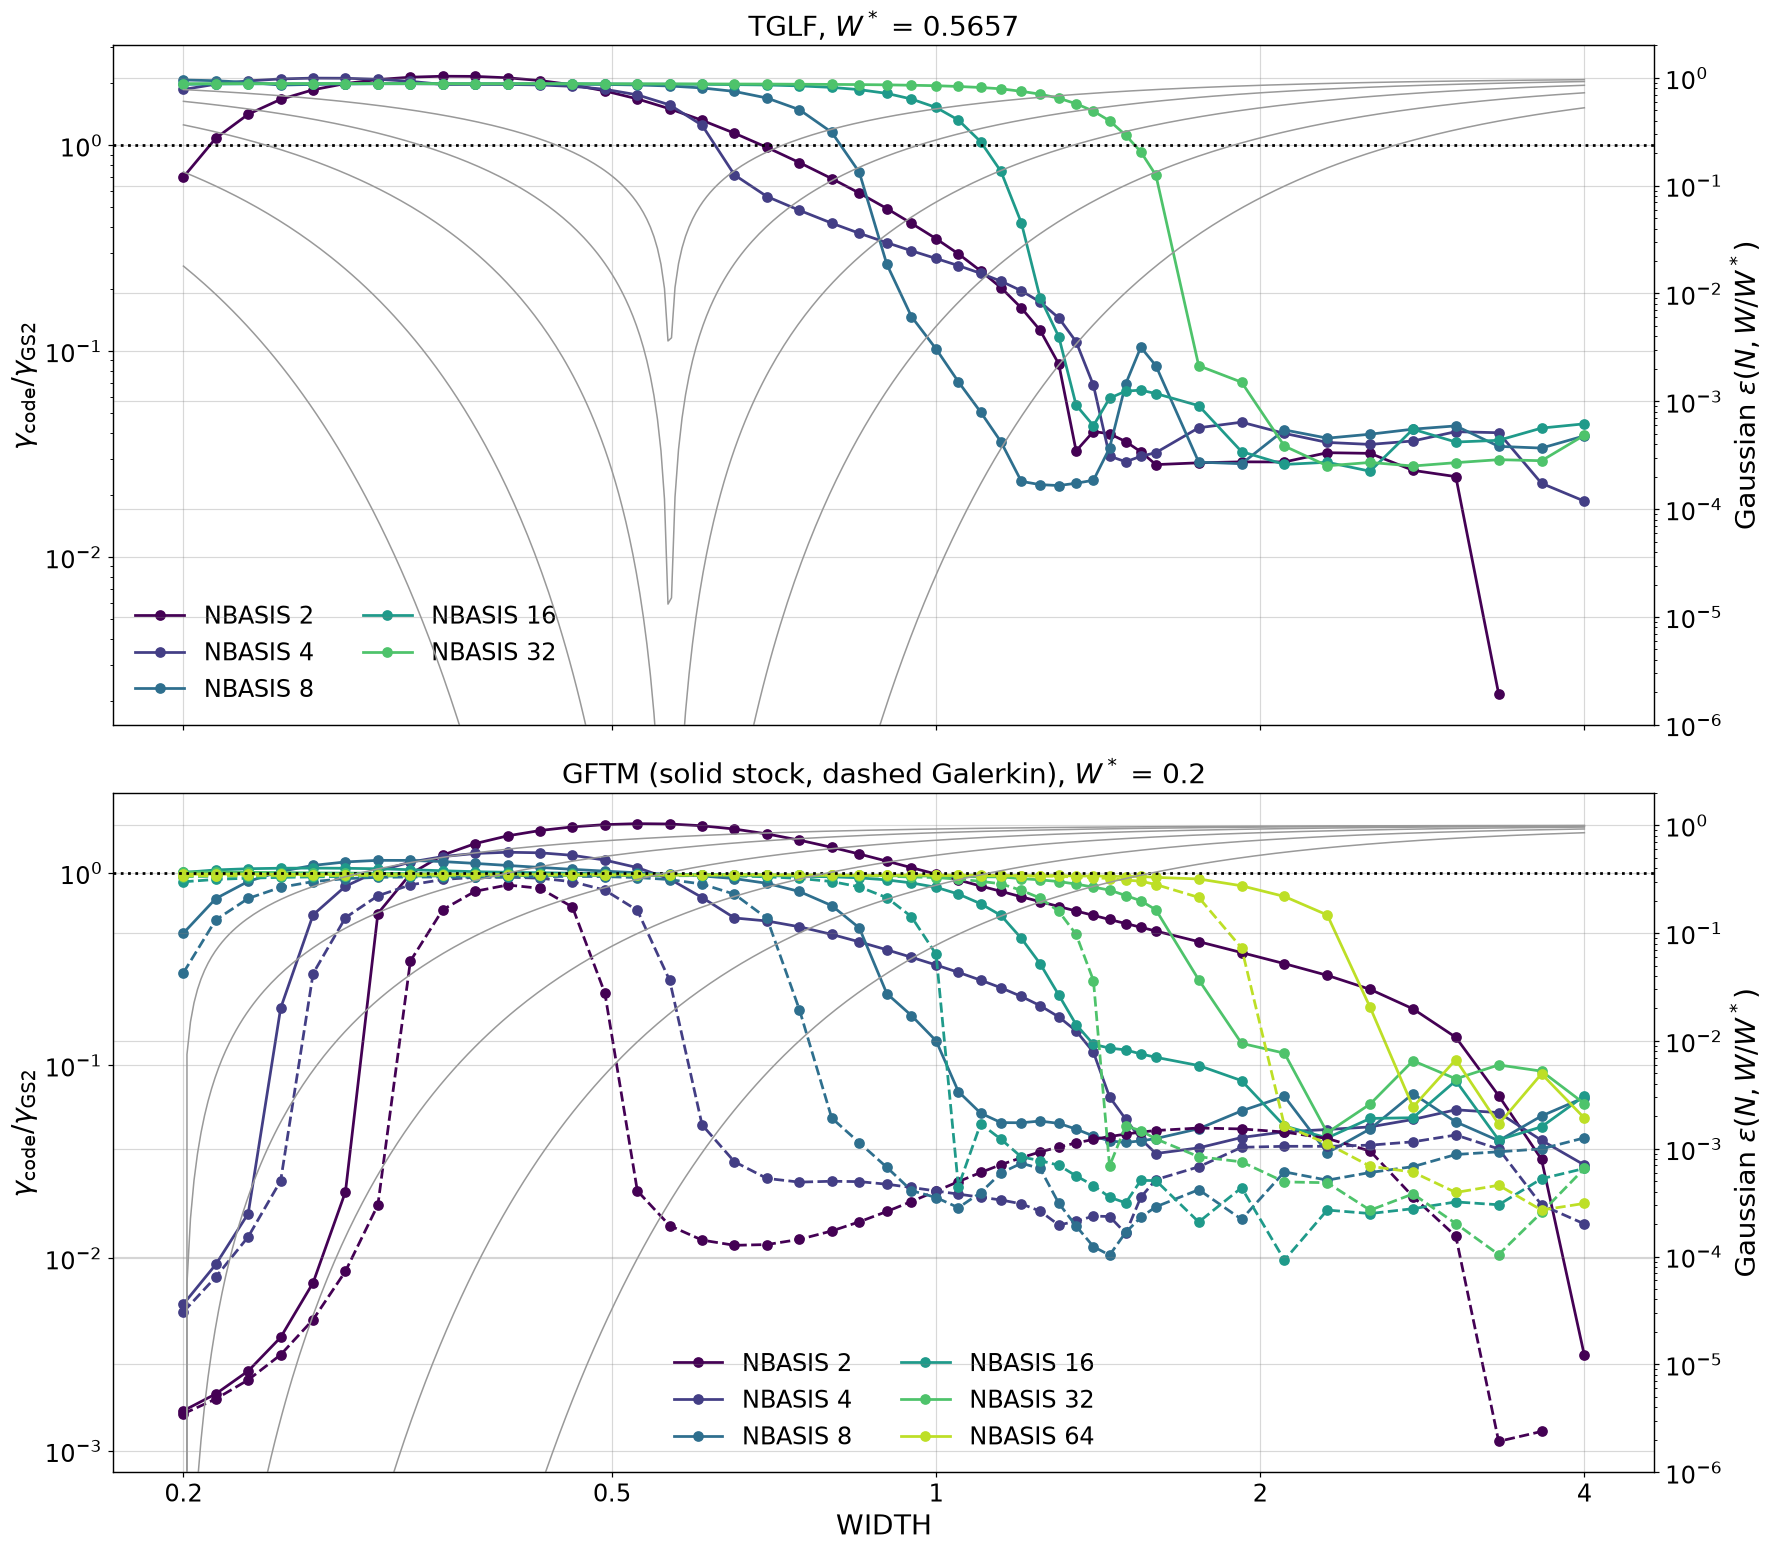

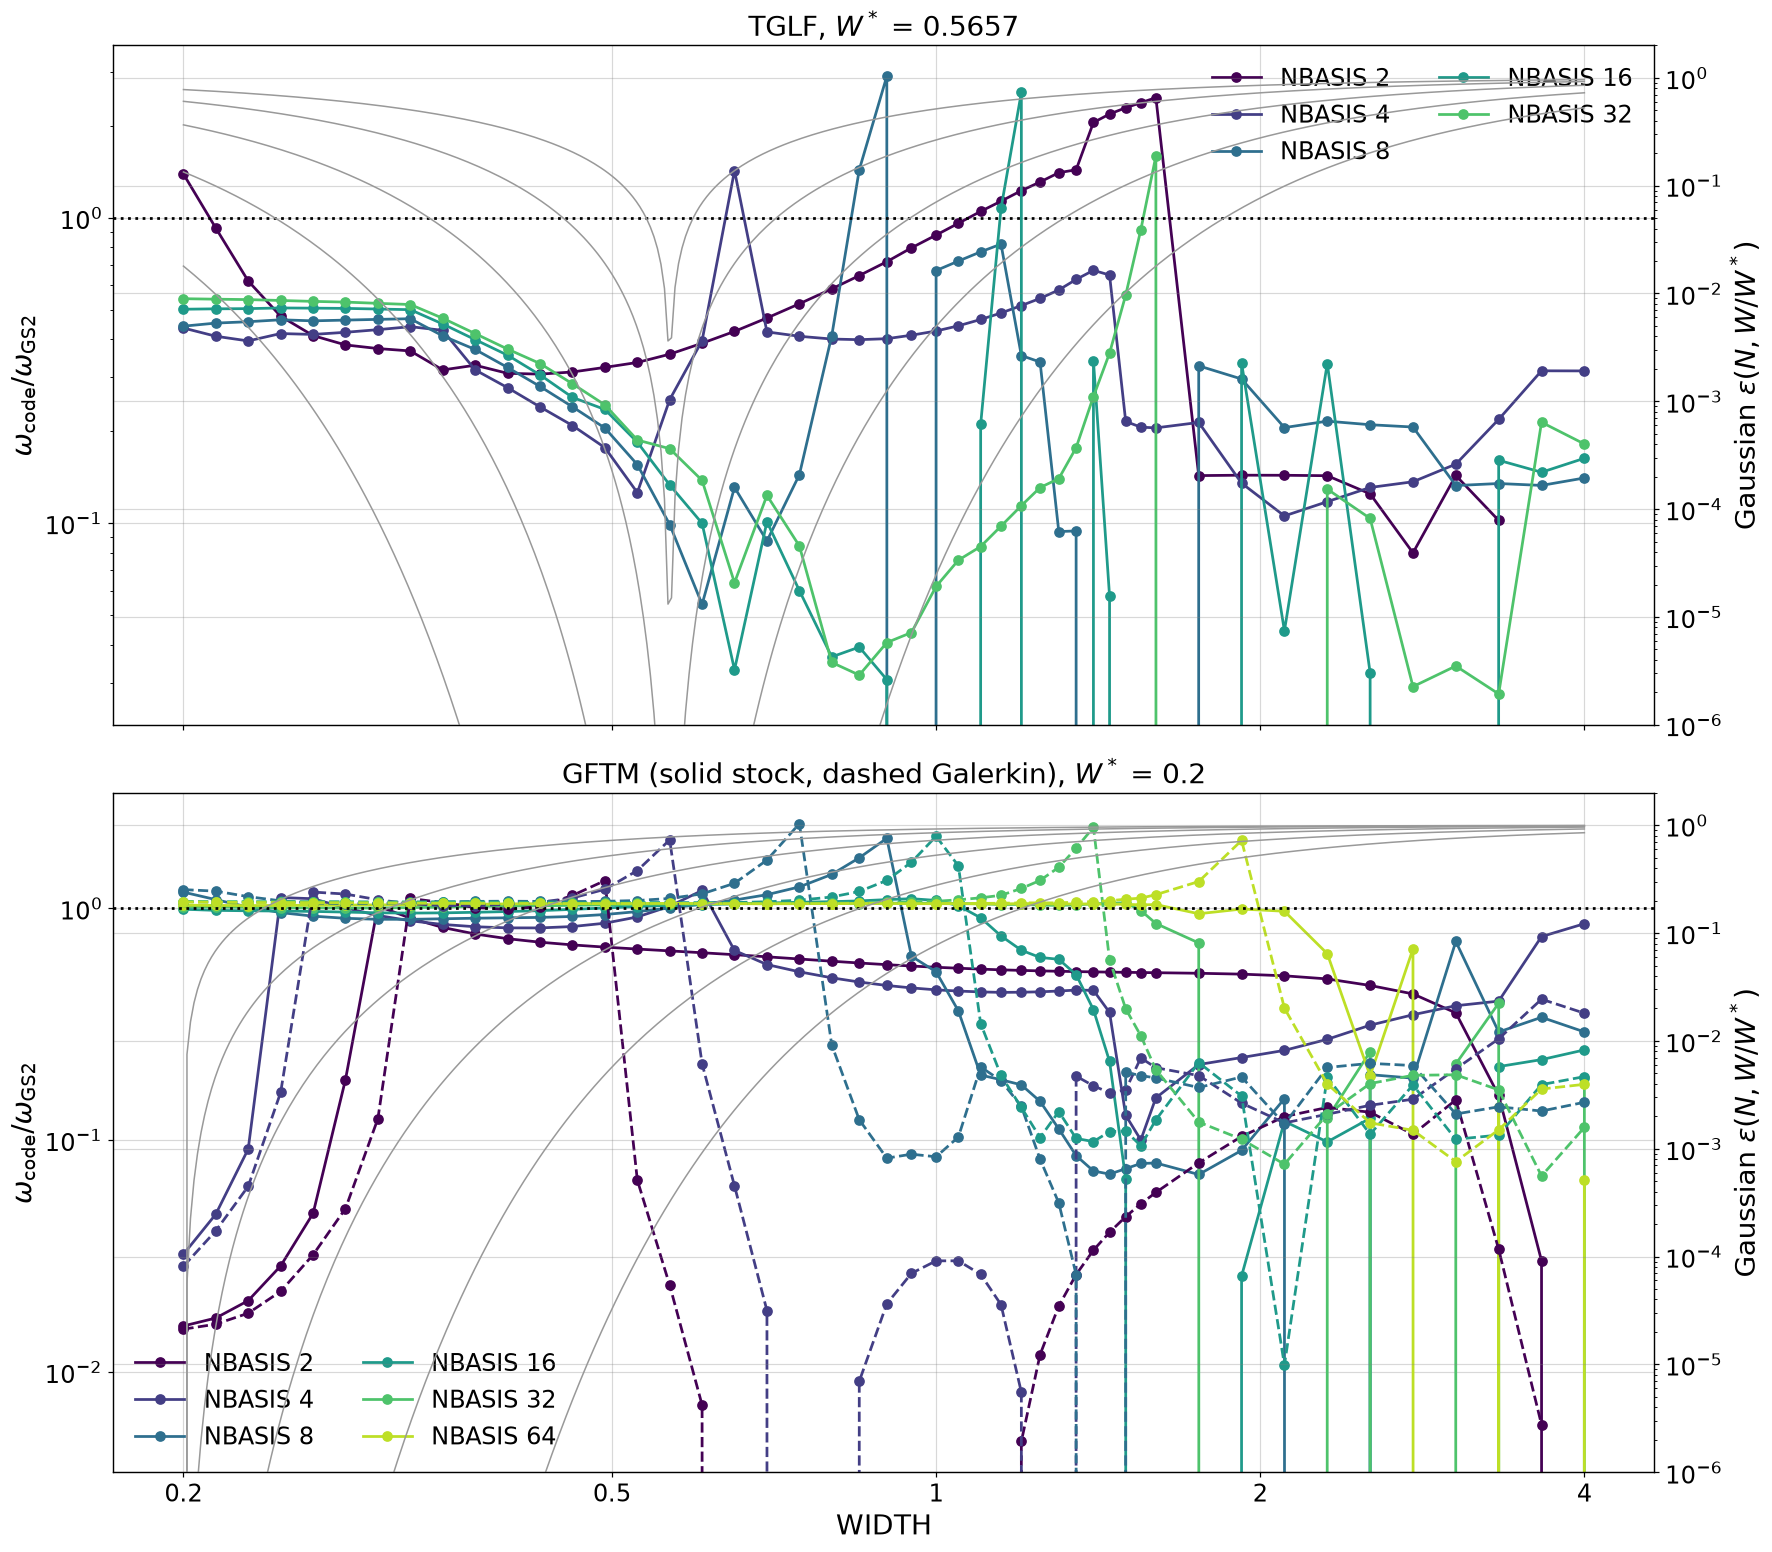

In [6]:
nbasis_colours = dict(zip(nbasis_all, plt.cm.viridis(np.linspace(0, 0.9, len(nbasis_all)))))
# W*: centre of the highest-NBASIS curve's plateau, the grid width where |dlog(gamma)/dlog(W)| is smallest (also used in 1c below)
w_star, gamma_star = {}, {}
for arm, nb_max in (("TGLF", 32), ("F", 64), ("T", 64)):
    top = table[(table.arm == arm) & (table.nb == nb_max) & (table.gamma > 0)]
    plateau = np.abs(np.gradient(np.log(top.gamma.values), np.log(top.W.values))).argmin()
    w_star[arm], gamma_star[arm] = float(top.W.values[plateau]), float(top.gamma.values[plateau])
print("W* (theory overlay centre):", w_star)
w_fine = np.geomspace(widths.min(), widths.max(), 400)


def u_shape(quantity, reference, ylabel):
    fig, axes = plt.subplots(2, 1, figsize=(16, 14), sharex=True)
    for ax, code_arms, centre in ((axes[0], {"TGLF": "-"}, w_star["TGLF"]), (axes[1], {"F": "-", "T": "--"}, w_star["F"])):
        for arm, ls in code_arms.items():
            for nb in nbasis_all:
                a = table[(table.arm == arm) & (table.nb == nb) & (table.gamma > 0)]
                if len(a):
                    ax.plot(a.W, a[quantity] / reference, color=nbasis_colours[nb], ls=ls,
                            label=f"NBASIS {nb}" if ls == "-" else None)
        ax.axhline(1, color="k", ls=":", marker="")
        ax.set(xscale="log", yscale="log", ylabel=ylabel)
        ax.set_title(("TGLF" if "TGLF" in code_arms else "GFTM (solid stock, dashed Galerkin)") + f", $W^*$ = {centre:g}", fontsize=fs_title)
        theory = ax.twinx()
        r = (np.square(w_fine / centre) - 1) / (np.square(w_fine / centre) + 1)
        for nb in nbasis_all if "TGLF" not in code_arms else nbasis_all[:-1]:
            theory.plot(w_fine, np.abs(r) ** (nb / 2), color="0.6", lw=1, marker="")
        theory.set(yscale="log", ylim=(1e-6, 2), ylabel=r"Gaussian $\varepsilon(N, W/W^*)$")
        ax.legend(fontsize=fs_legend, ncol=2)
    axes[1].set_xlabel("WIDTH")
    log_xticks(axes[1], [0.2, 0.5, 1, 2, 4])
    plt.show()
    return fig


fig1c = u_shape("gamma", gamma_gs2, r"$\gamma_{\rm code}/\gamma_{\rm GS2}$")
fig1d = u_shape("omega", omega_gs2, r"$\omega_{\rm code}/\omega_{\rm GS2}$")

### 1c. Numerical error only: self-convergence against the Gaussian-mismatch prediction

The error against GS2 cannot fall below the model's own disagreement with GS2, while the Gaussian $\varepsilon$ goes to 0.
So here each arm is compared with itself: $|\gamma(W, N)/\gamma_{\rm ref} - 1|$, with $\gamma_{\rm ref} = \gamma(W^*, N_{\max})$, the
arm's highest NBASIS (TGLF 32, GFTM 64) at its best width $W^*$. $W^*$ is the centre of that curve's plateau: the grid width
where $|\mathrm{d}\log\gamma/\mathrm{d}\log W|$ at $N_{\max}$ is smallest. The grey curves are $|r|^{N/2}$ centred at the same
$W^*$, plotted on the same axis. Their heights carry no fitted constant, so only the shape compares: if the KBM needs more
basis functions than a Gaussian, the data U is narrower than the grey curve at the same $N$ and falls more slowly with $N$.

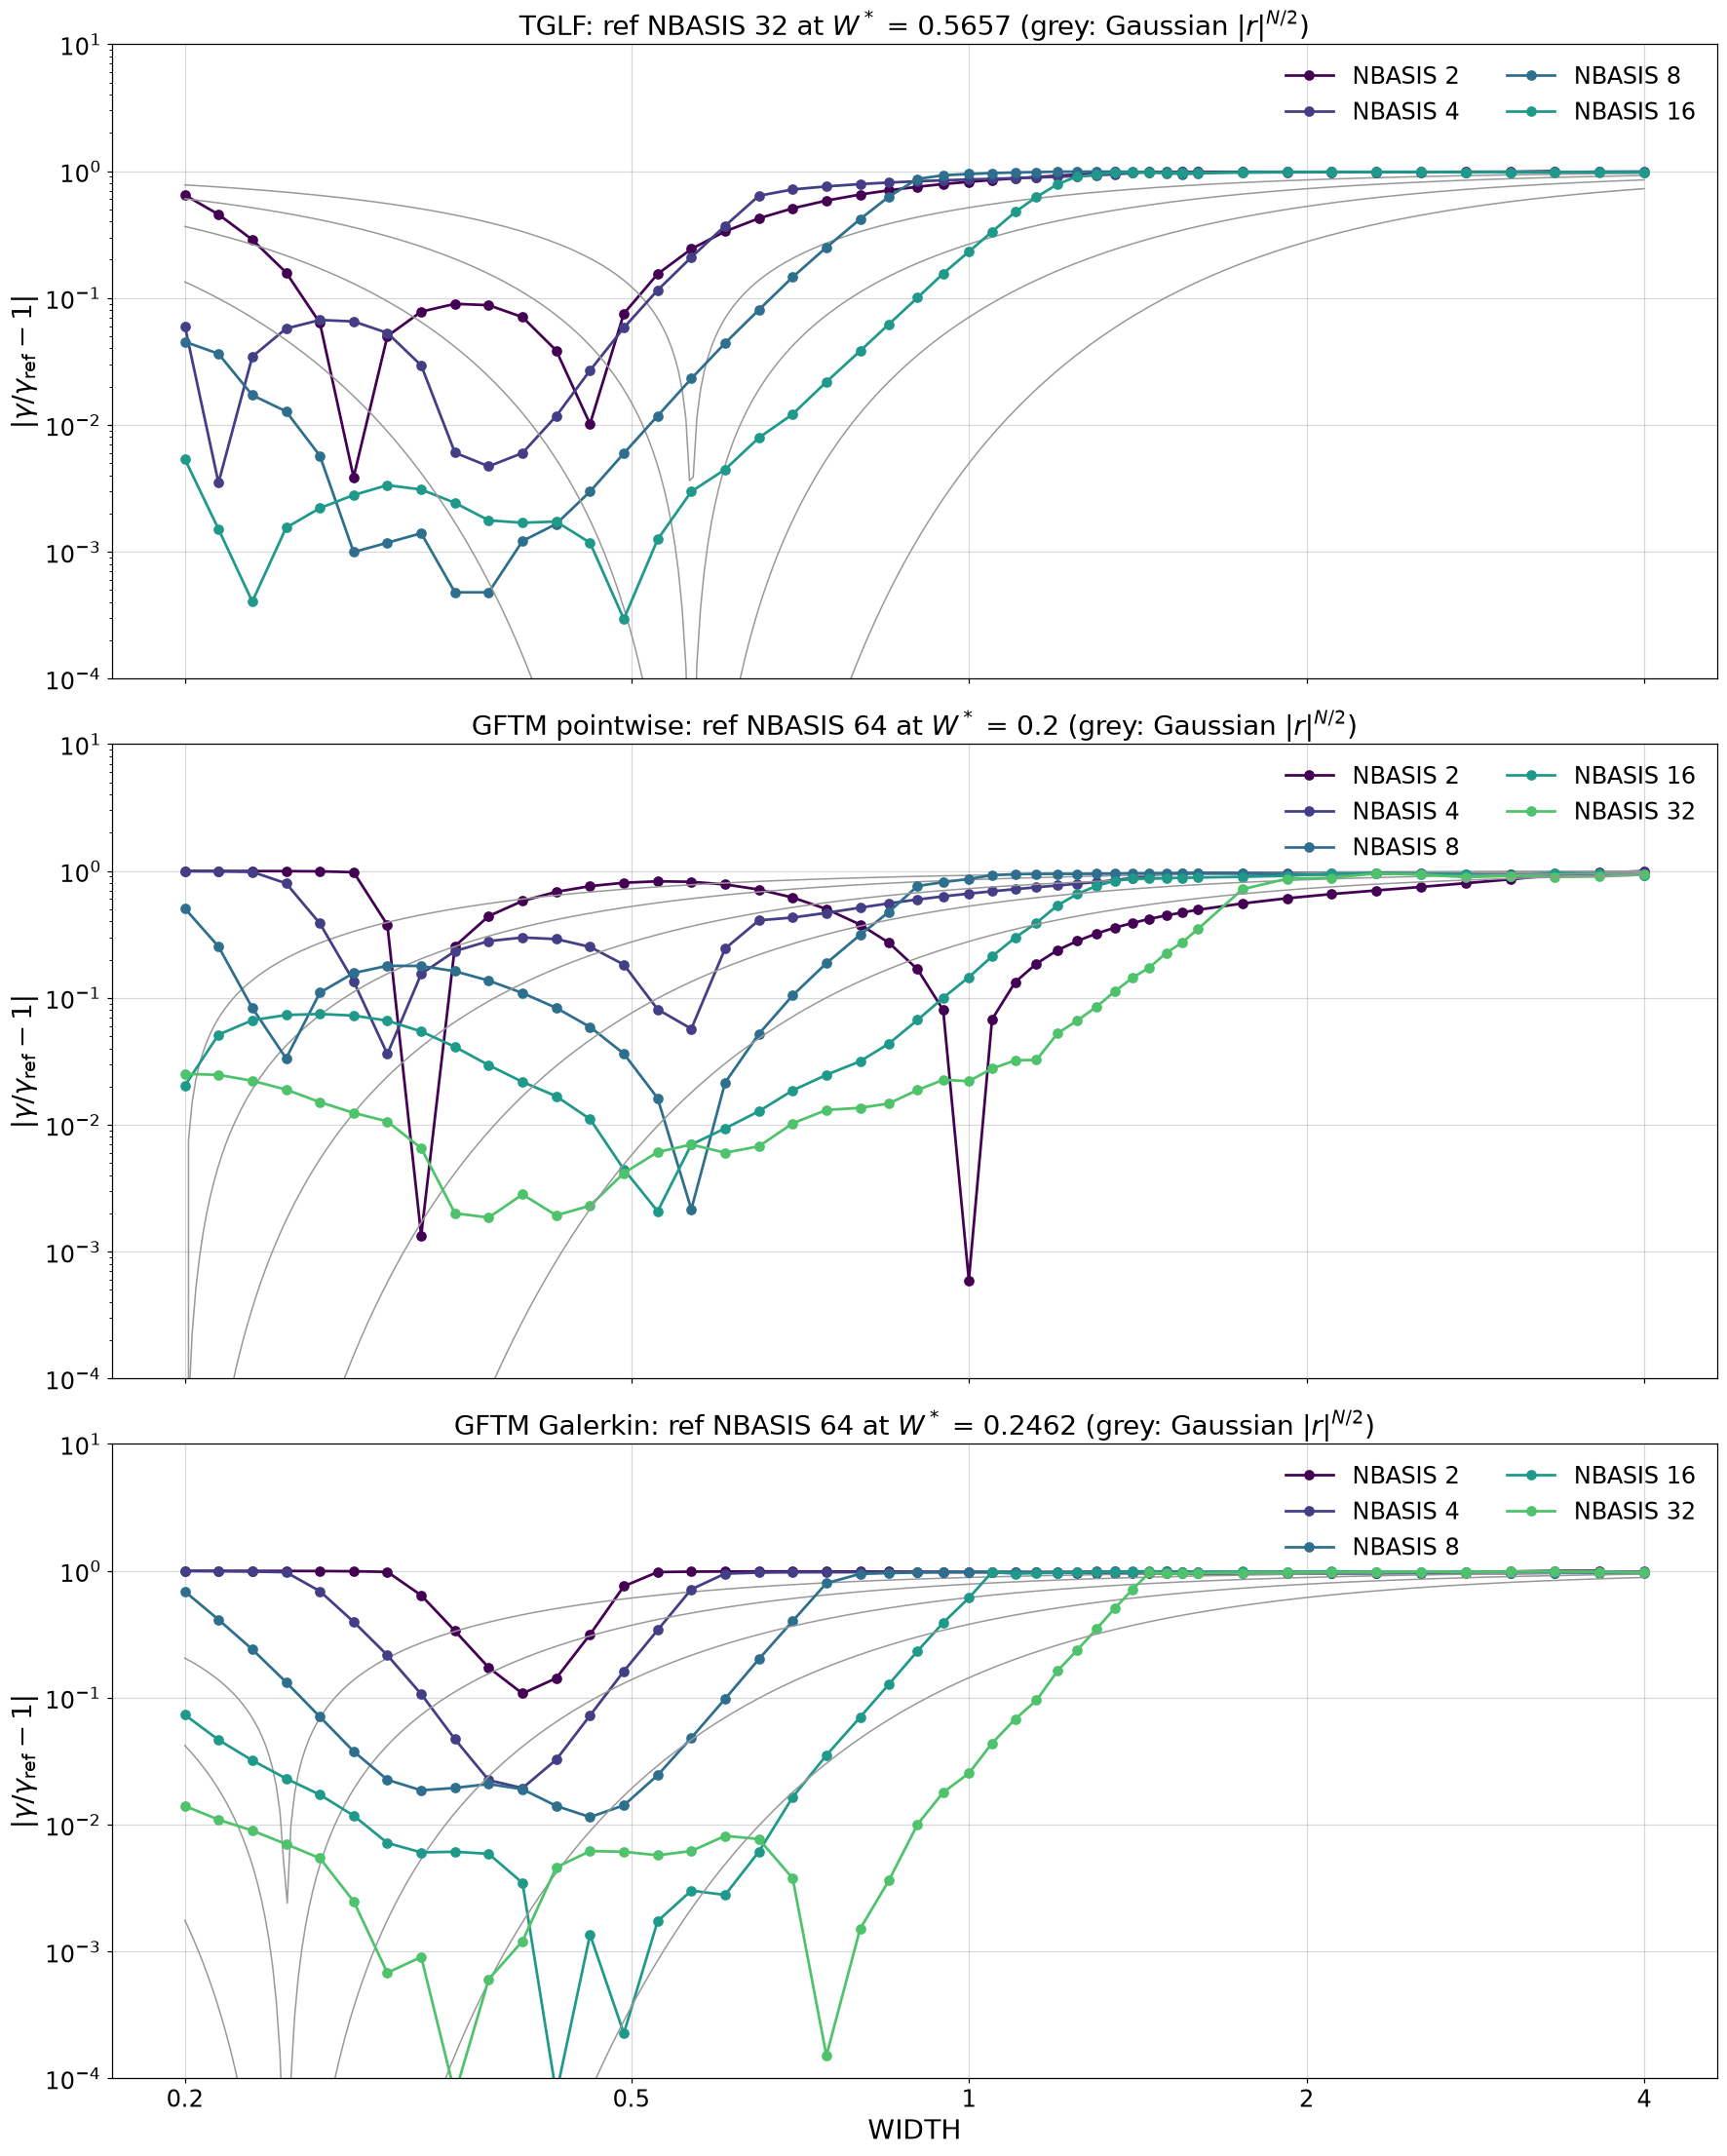

                      TGLF       F       T
w_star              0.5657  0.2000  0.2462
gamma_ref           2.7203  1.3484  1.3273
gamma_ref_over_gs2  1.9844  0.9836  0.9682


In [7]:
fig1e, axes1e = plt.subplots(3, 1, figsize=(16, 20), sharex=True)
self_reference = {}
for ax, (arm, nb_max) in zip(axes1e, (("TGLF", 32), ("F", 64), ("T", 64))):
    centre, gamma_ref = w_star[arm], gamma_star[arm]
    self_reference[arm] = dict(w_star=centre, gamma_ref=gamma_ref, gamma_ref_over_gs2=gamma_ref / gamma_gs2)
    r = (np.square(w_fine / centre) - 1) / (np.square(w_fine / centre) + 1)
    for nb in nbasis_all:
        a = table[(table.arm == arm) & (table.nb == nb) & (table.gamma > 0)]
        if len(a) and nb < nb_max:
            ax.plot(a.W, np.abs(a.gamma / gamma_ref - 1), color=nbasis_colours[nb], label=f"NBASIS {nb}")
            ax.plot(w_fine, np.abs(r) ** (nb / 2), color="0.6", lw=1, marker="")
    ax.set(xscale="log", yscale="log", ylim=(1e-4, 10), ylabel=rf"$|\gamma/\gamma_{{\rm ref}}-1|$")
    ax.set_title(f"{arms[arm]}: ref NBASIS {nb_max} at $W^*$ = {centre:g} (grey: Gaussian $|r|^{{N/2}}$)", fontsize=fs_title)
    ax.legend(fontsize=fs_legend, ncol=2)
axes1e[-1].set_xlabel("WIDTH")
log_xticks(axes1e[-1], [0.2, 0.5, 1, 2, 4])
plt.show()
print(pd.DataFrame(self_reference).round(4).to_string())

## 2. Eigenfunctions: under-resolution and wrong width, seen directly

$|\phi|(\theta)$ and $|A_\parallel|(\theta)$, each normalised to its maximum, GFTM (both arms) and TGLF against GS2, at four widths
(0.2, the Galerkin max-$\gamma$ width at NBASIS 16, 1.6, 3.33) and three NBASIS. Panel titles
give $\gamma$ of each arm; GS2's $\gamma$ is in the figure title.

widths shown: [0.2, 0.4595, 1.6, 3.3302]


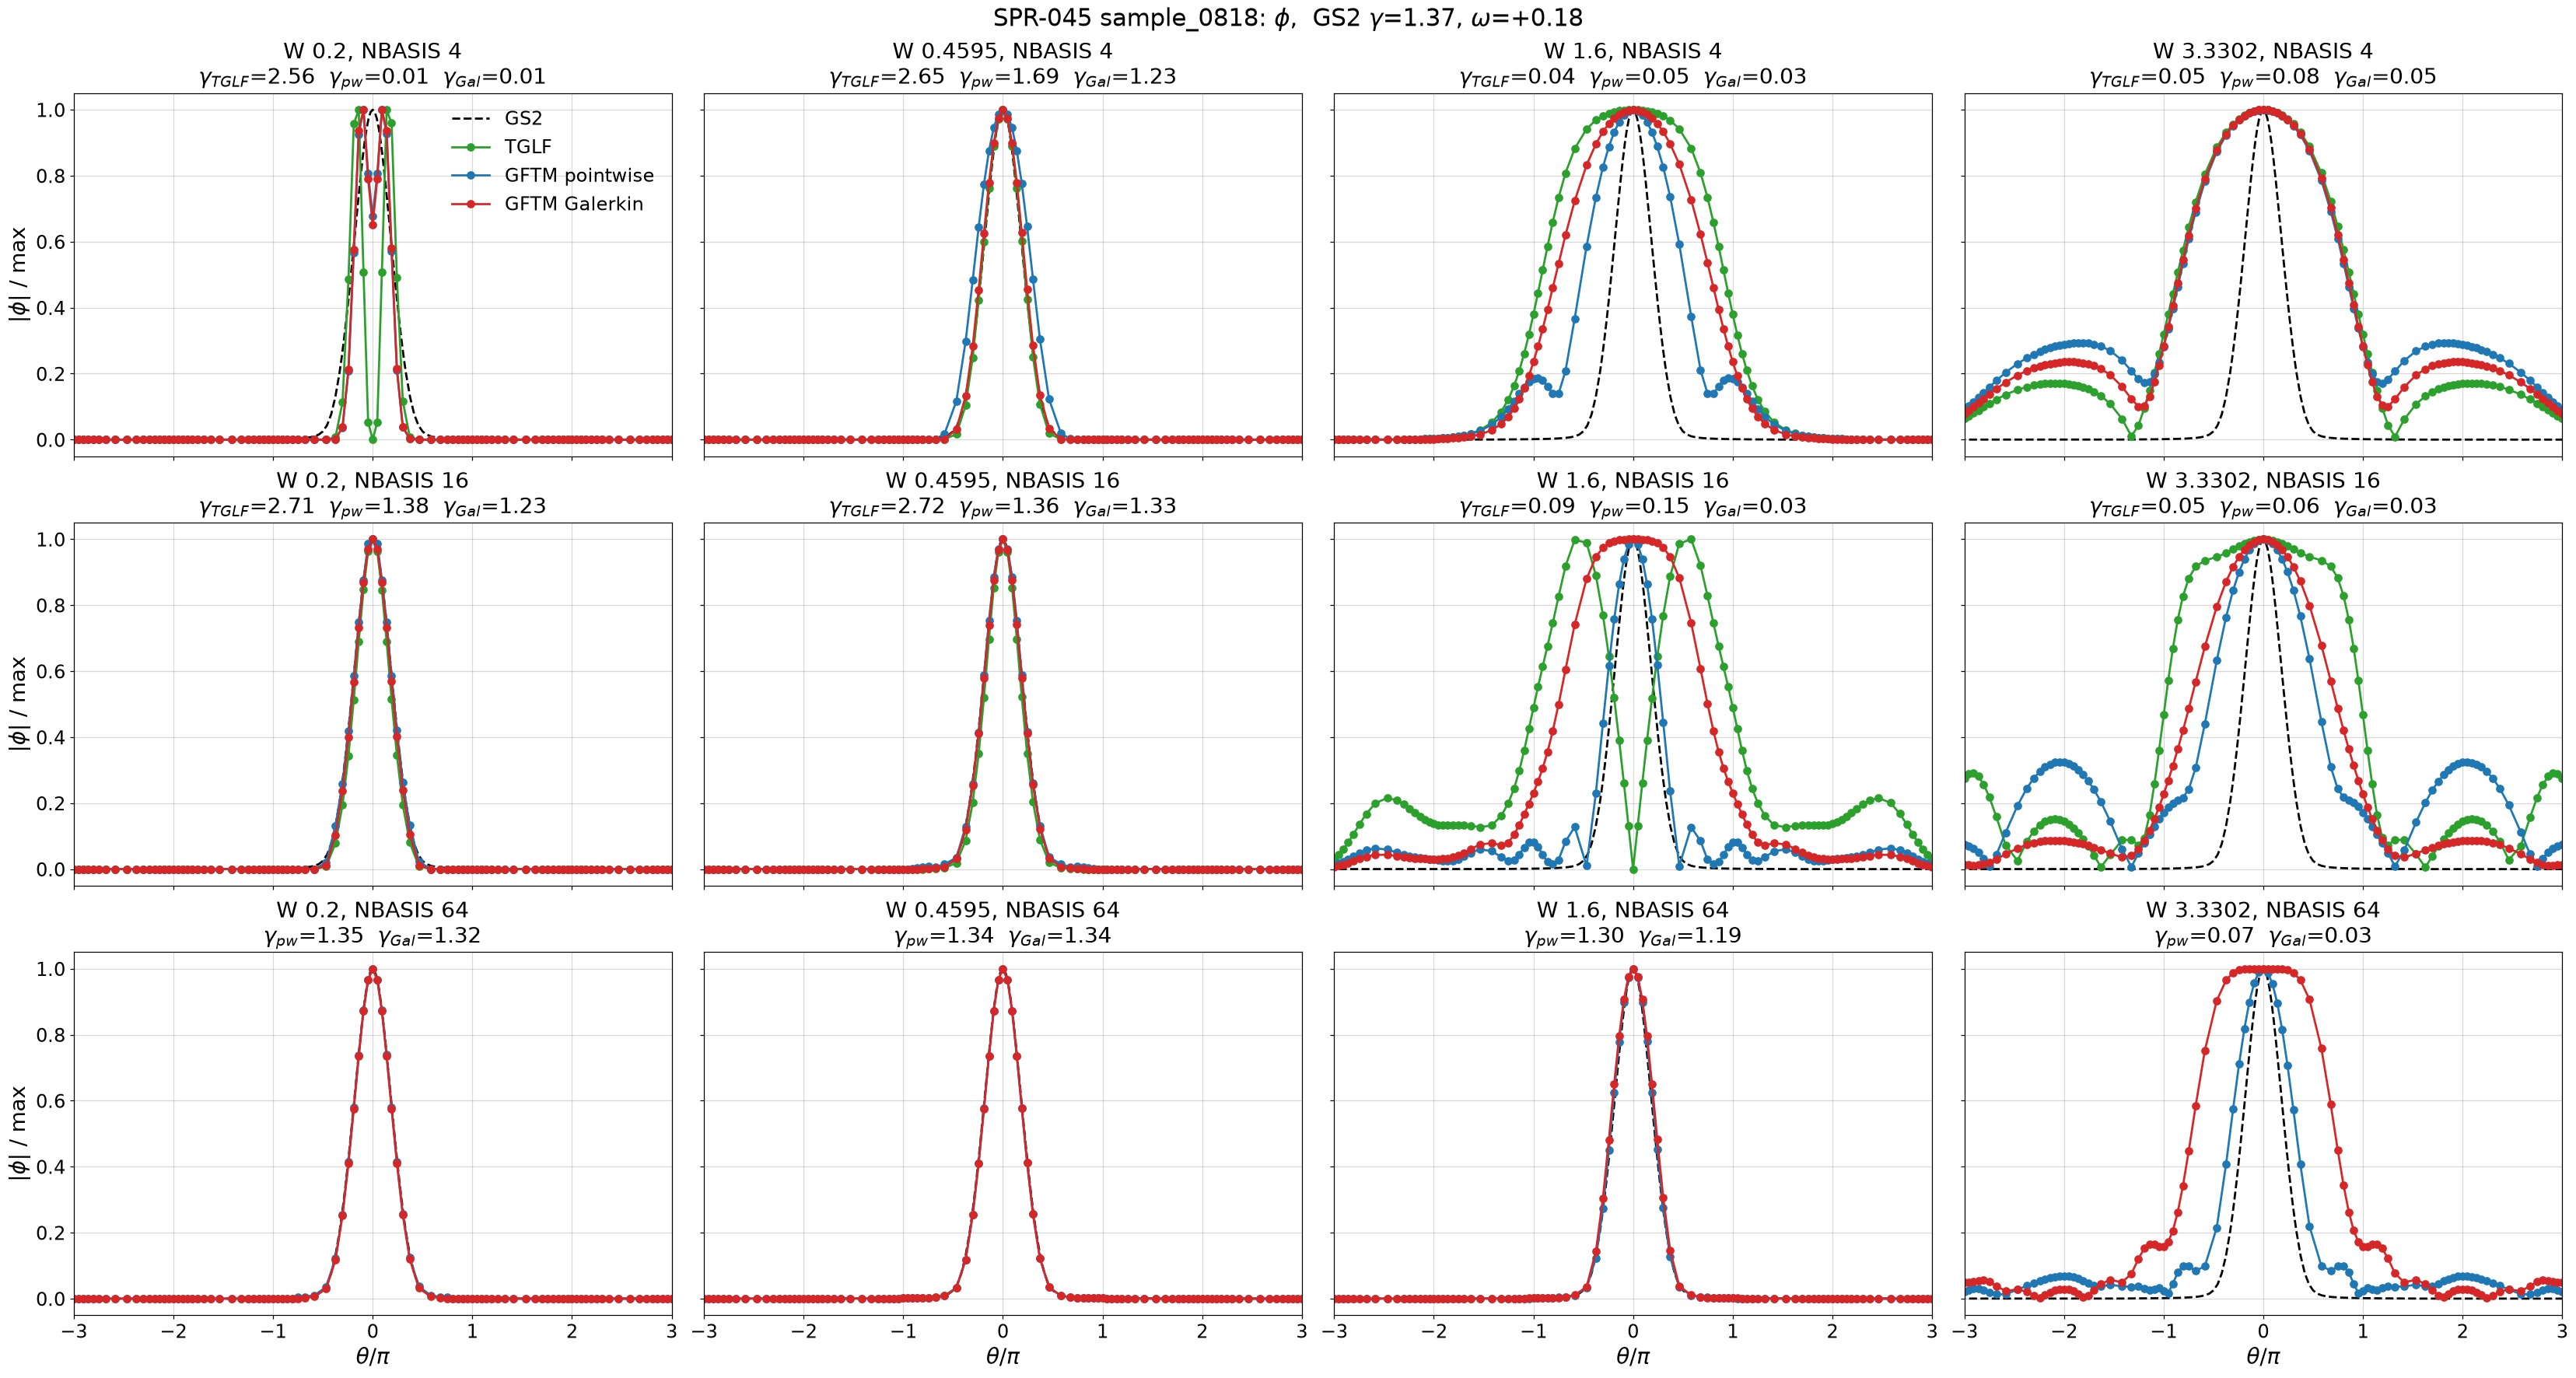

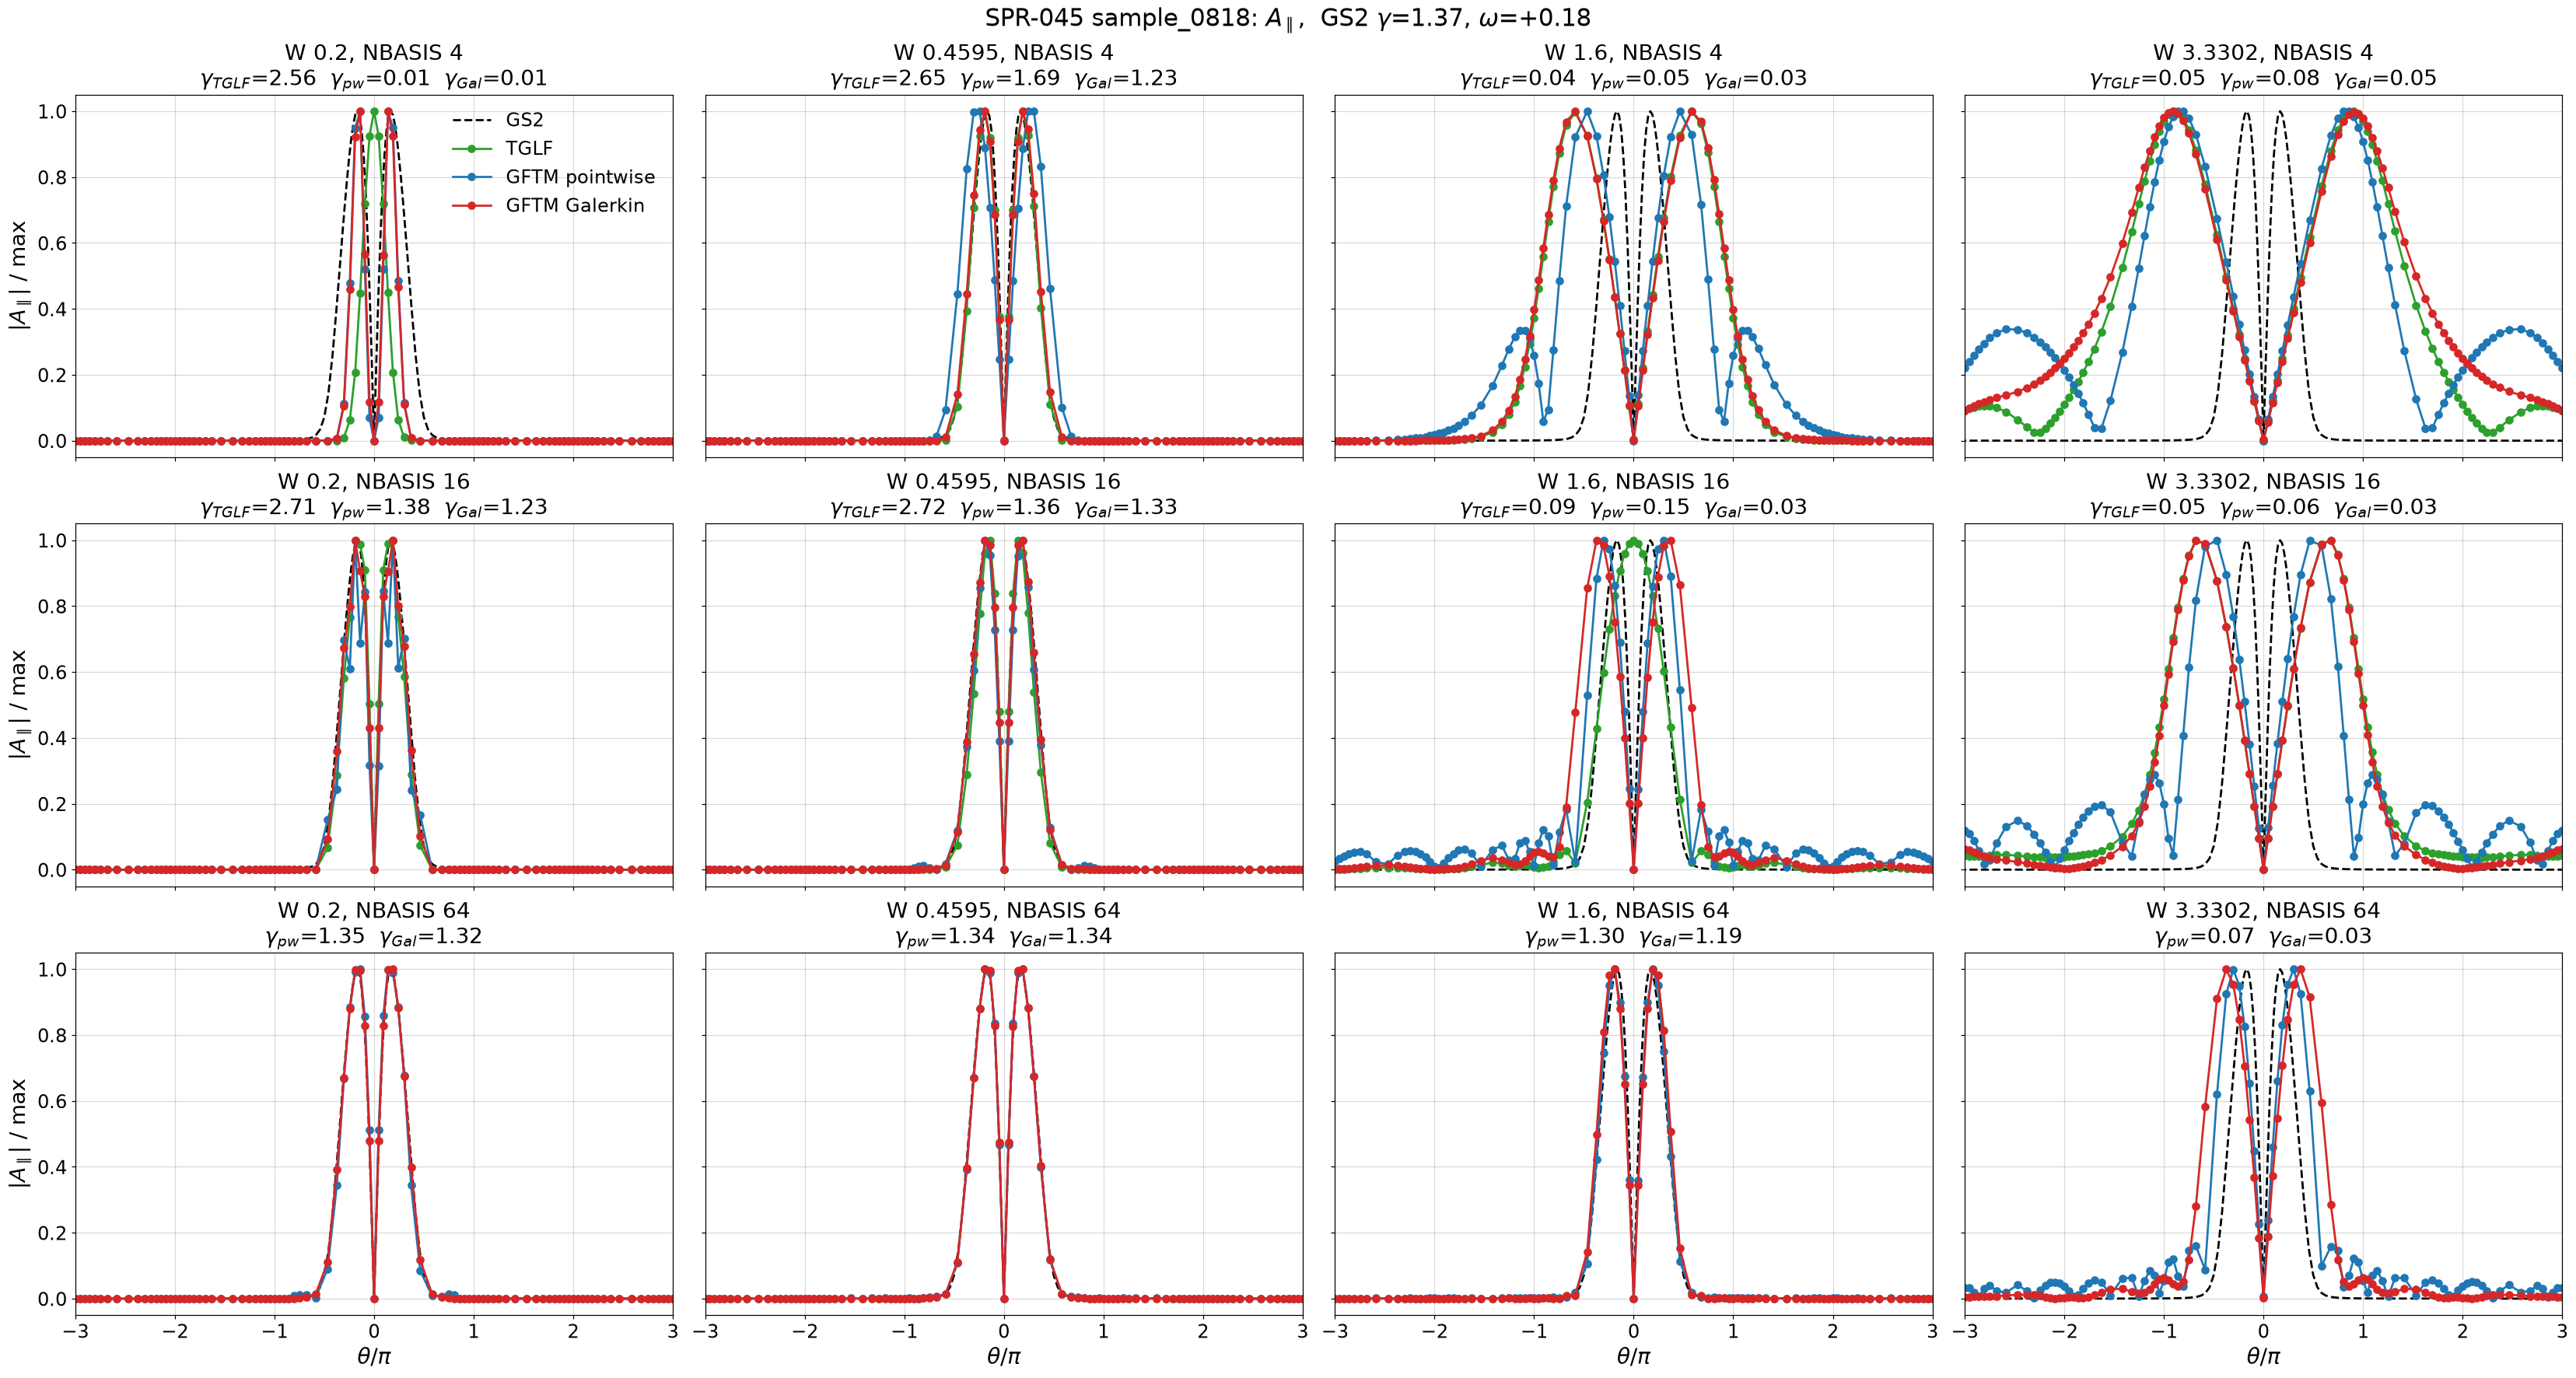

In [8]:
# "good" width: the Galerkin max-gamma width at NBASIS 16
galerkin_16 = table[(table.arm == "T") & (table.nb == 16)]
w_good = float(galerkin_16.W.values[galerkin_16.gamma.values.argmax()])
show_widths, show_nbasis = [0.2, w_good, 1.6, 3.3302], [4, 16, 64]
print("widths shown:", show_widths)


def eigenfunction_panels(field):
    fig, axes = plt.subplots(len(show_nbasis), len(show_widths), figsize=(30, 16), sharex=True, sharey=True, squeeze=False)
    gs2_amplitude = np.sqrt(gs2_power[field] / gs2_power[field].max())
    for r, nb in enumerate(show_nbasis):
        for j, width in enumerate(show_widths):
            ax = axes[r, j]
            ax.plot(gs2_amplitude.theta / np.pi, gs2_amplitude, color="k", ls="--", marker="", label="GS2")
            title = []
            for arm in ["TGLF", "F", "T"]:
                rows_here = table[(table.arm == arm) & (table.nb == nb) & np.isclose(table.W, width)]
                if not len(rows_here):
                    continue        # TGLF has no NBASIS 64
                row = rows_here.iloc[0]
                output = outputs[arm].isel(sample=int(row.sample_index))
                mode = output.isel(mode=output.growth_rate.fillna(-np.inf).argmax("mode"))
                amplitude = np.abs(mode.eigenfunctions.sel(field=field)).squeeze()
                ax.plot(mode.theta / np.pi, amplitude / amplitude.max(), color=arm_colours[arm], label=arms[arm])
                title.append(rf"$\gamma_{{{dict(F='pw', T='Gal', TGLF='TGLF')[arm]}}}$={row.gamma:.2f}")
            ax.set_title(f"W {width:g}, NBASIS {nb}\n" + "  ".join(title), fontsize=fs_title)
            ax.set_xlim(-3, 3)
            if r == len(show_nbasis) - 1:
                ax.set_xlabel(r"$\theta/\pi$")
        axes[r, 0].set_ylabel(f"|{field_labels[field]}| / max")
    axes[0, 0].legend(fontsize=fs_legend)
    fig.suptitle(rf"SPR-045 {sample}: {field_labels[field]},  GS2 $\gamma$={gamma_gs2:.2f}, $\omega$={omega_gs2:+.2f}", fontsize=20)
    plt.show()
    return fig


fig2 = eigenfunction_panels("phi")
fig2b = eigenfunction_panels("apar")

## 3. Extent ratio against WIDTH per NBASIS

Format copied from fig6 of `gftm_quadrature_extent.ipynb` (`per_nbasis`: columns = NBASIS, log WIDTH axis), rows =
$\phi$, $A_\parallel$, $B_\parallel$. One mode, so the signed $\log_{10}$(Extent Ratio) is plotted (0 = GS2's extent;
above = too wide) instead of the population median of its modulus.

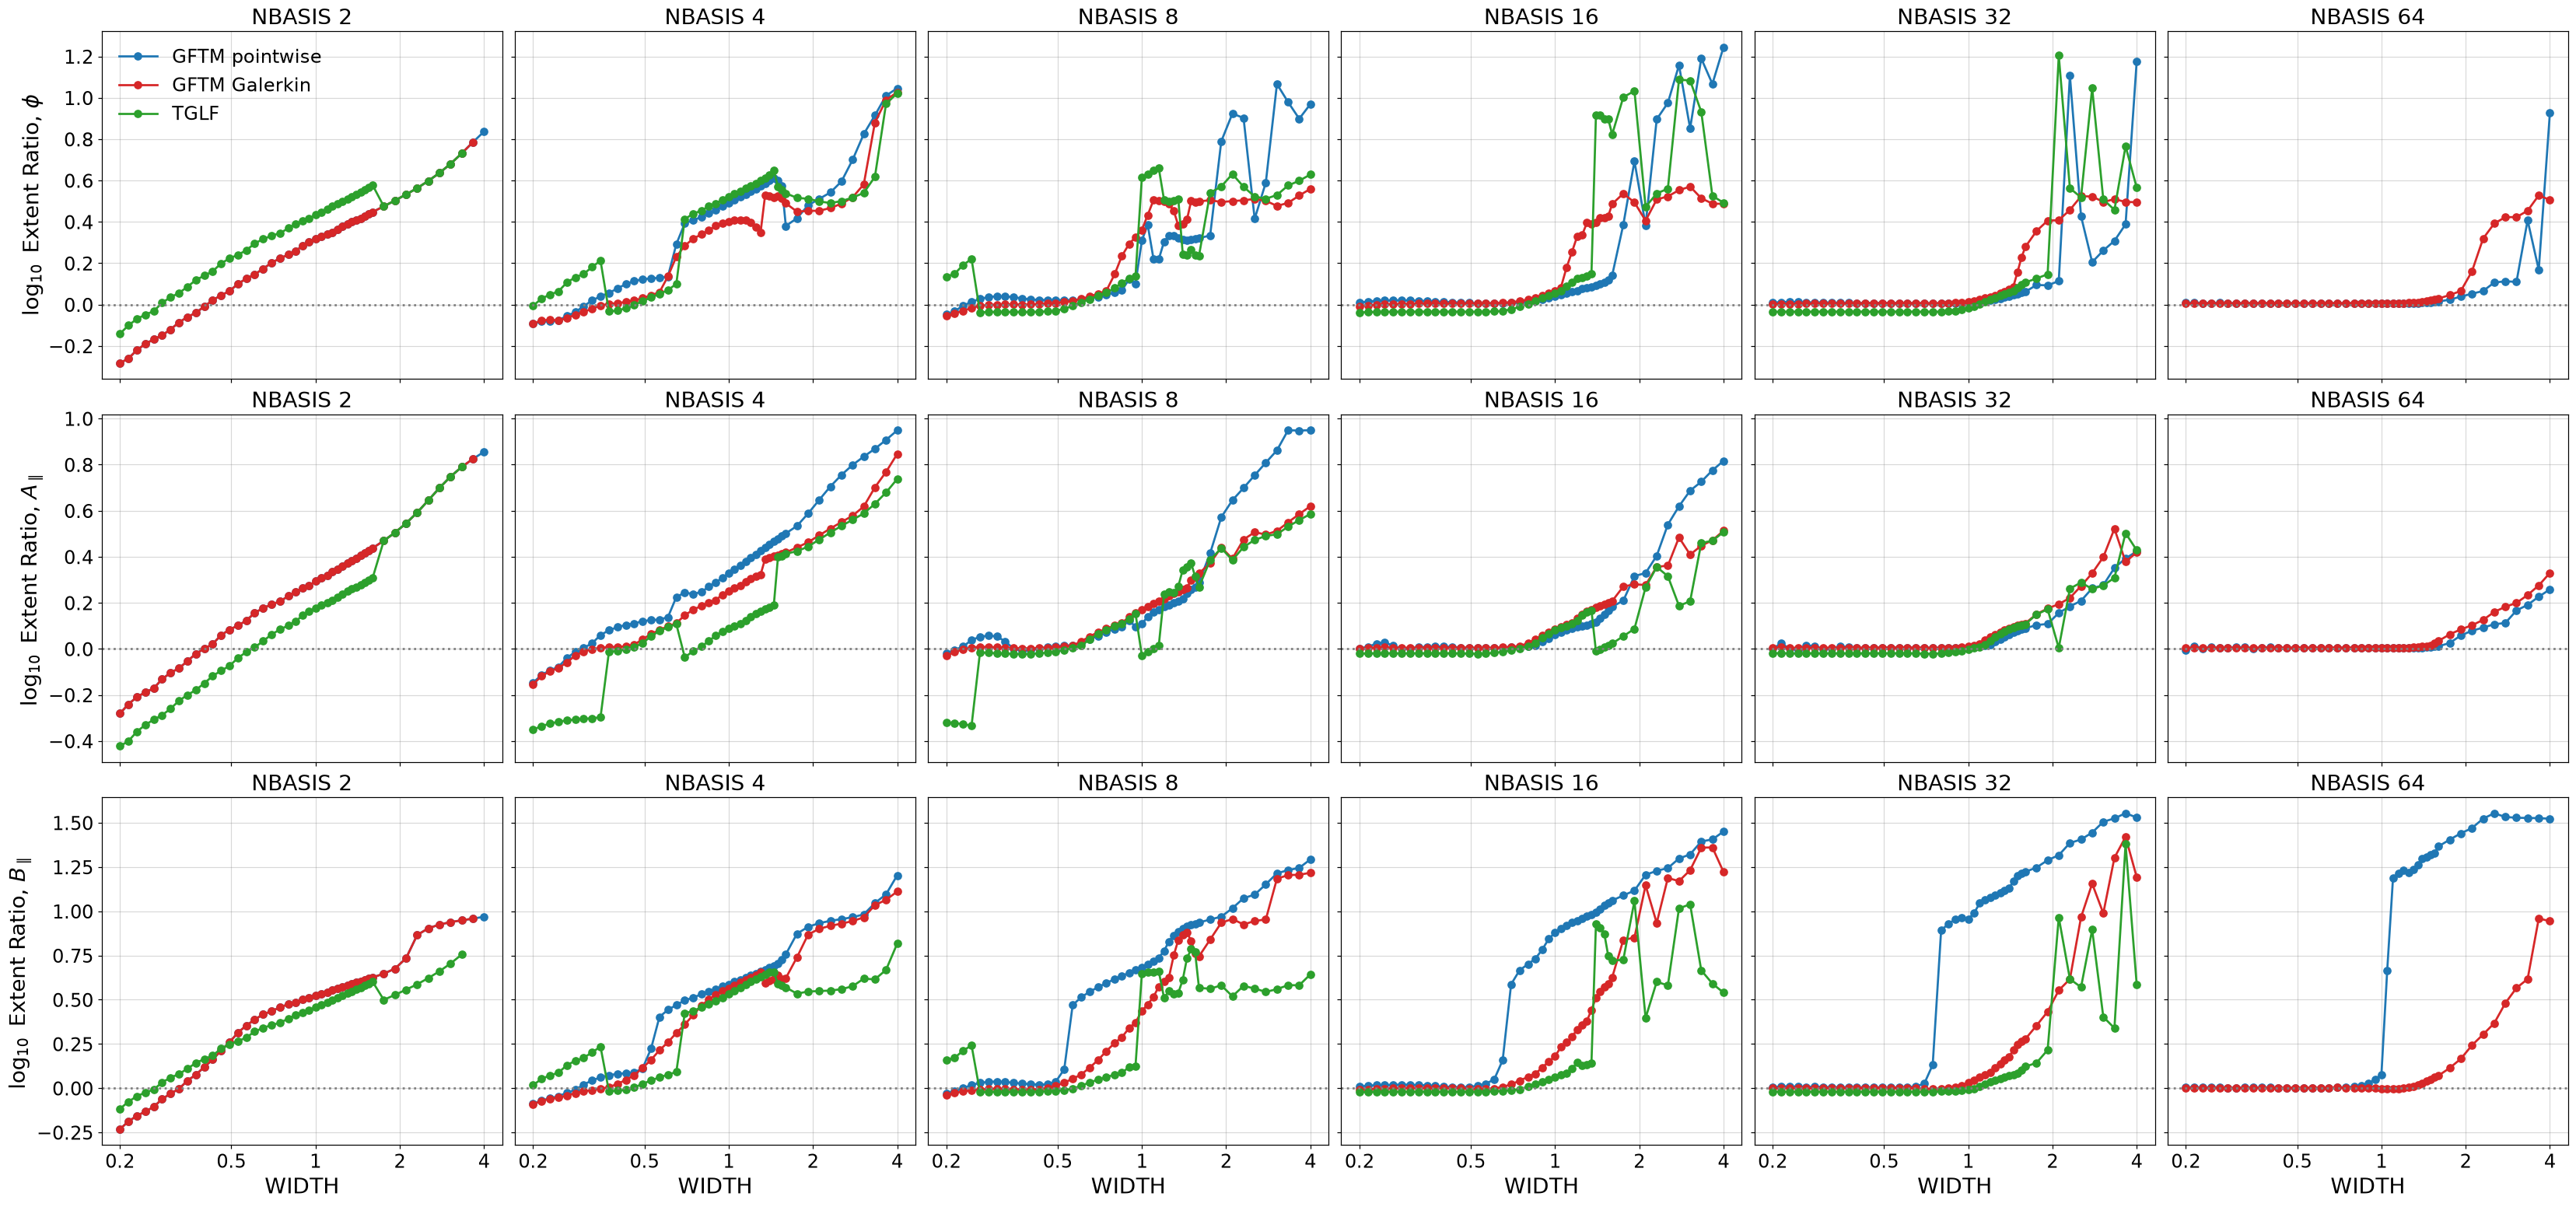

In [9]:
fig3, _ = per_nbasis(table, [f"log_extent_ratio_{field}" for field in fields],
                     [rf"$\log_{{10}}$ Extent Ratio, {field_labels[field]}" for field in fields], hline=0, figsize=(30, 14))
plt.show()

## 4. Width selection against NBASIS

Analogue of qp5.24 fig2 / fig3 / fig3b for one mode. Per arm and NBASIS:
- $W_{\rm sel}(N) = \arg\max_W \gamma(W, N)$ (the max-$\gamma$ selection);
- $W_\gamma(N)$: the width whose $\gamma$ is closest to GS2 (an oracle);
- $W_{\rm ext}(N)$: the width whose $\phi$ extent is closest to GS2's (an oracle);
- TGLF's own FIND_WIDTH choice (stars, at NBASIS_MIN).

Middle: $\gamma$ at $W_{\rm sel}(N)$ against GS2. Right: $\phi$ extent ratio at $W_{\rm sel}(N)$.

 arm  nb  w_sel  w_gamma  w_ext  gamma_sel  omega_sel  log_extent_ratio_sel
   F   2 0.5279   0.3249 0.4000     2.4649     0.1173                0.1002
   F   4 0.4000   0.3031 0.3031     1.7511     0.1448                0.0776
   F   8 0.3031   0.5279 0.2297     1.5895     0.1576                0.0406
   F  16 0.2639   0.4287 0.5657     1.4489     0.1705                0.0207
   F  32 0.2000   0.2639 0.8000     1.3823     0.1787                0.0100
   F  64 0.2000   0.2000 1.2000     1.3484     0.1813                0.0084
   T   2 0.4000   0.4000 0.4000     1.1842     0.1739               -0.0098
   T   4 0.4000   0.4000 0.3732     1.3016     0.1828                0.0075
   T   8 0.4595   0.4595 0.3732     1.3121     0.1880                0.0052
   T  16 0.4595   0.4595 0.2297     1.3291     0.1860                0.0054
   T  32 0.6063   0.6063 0.2000     1.3381     0.1840                0.0069
   T  64 0.4595   0.4595 0.2000     1.3352     0.1842                0.0066
TGLF   2 0.3

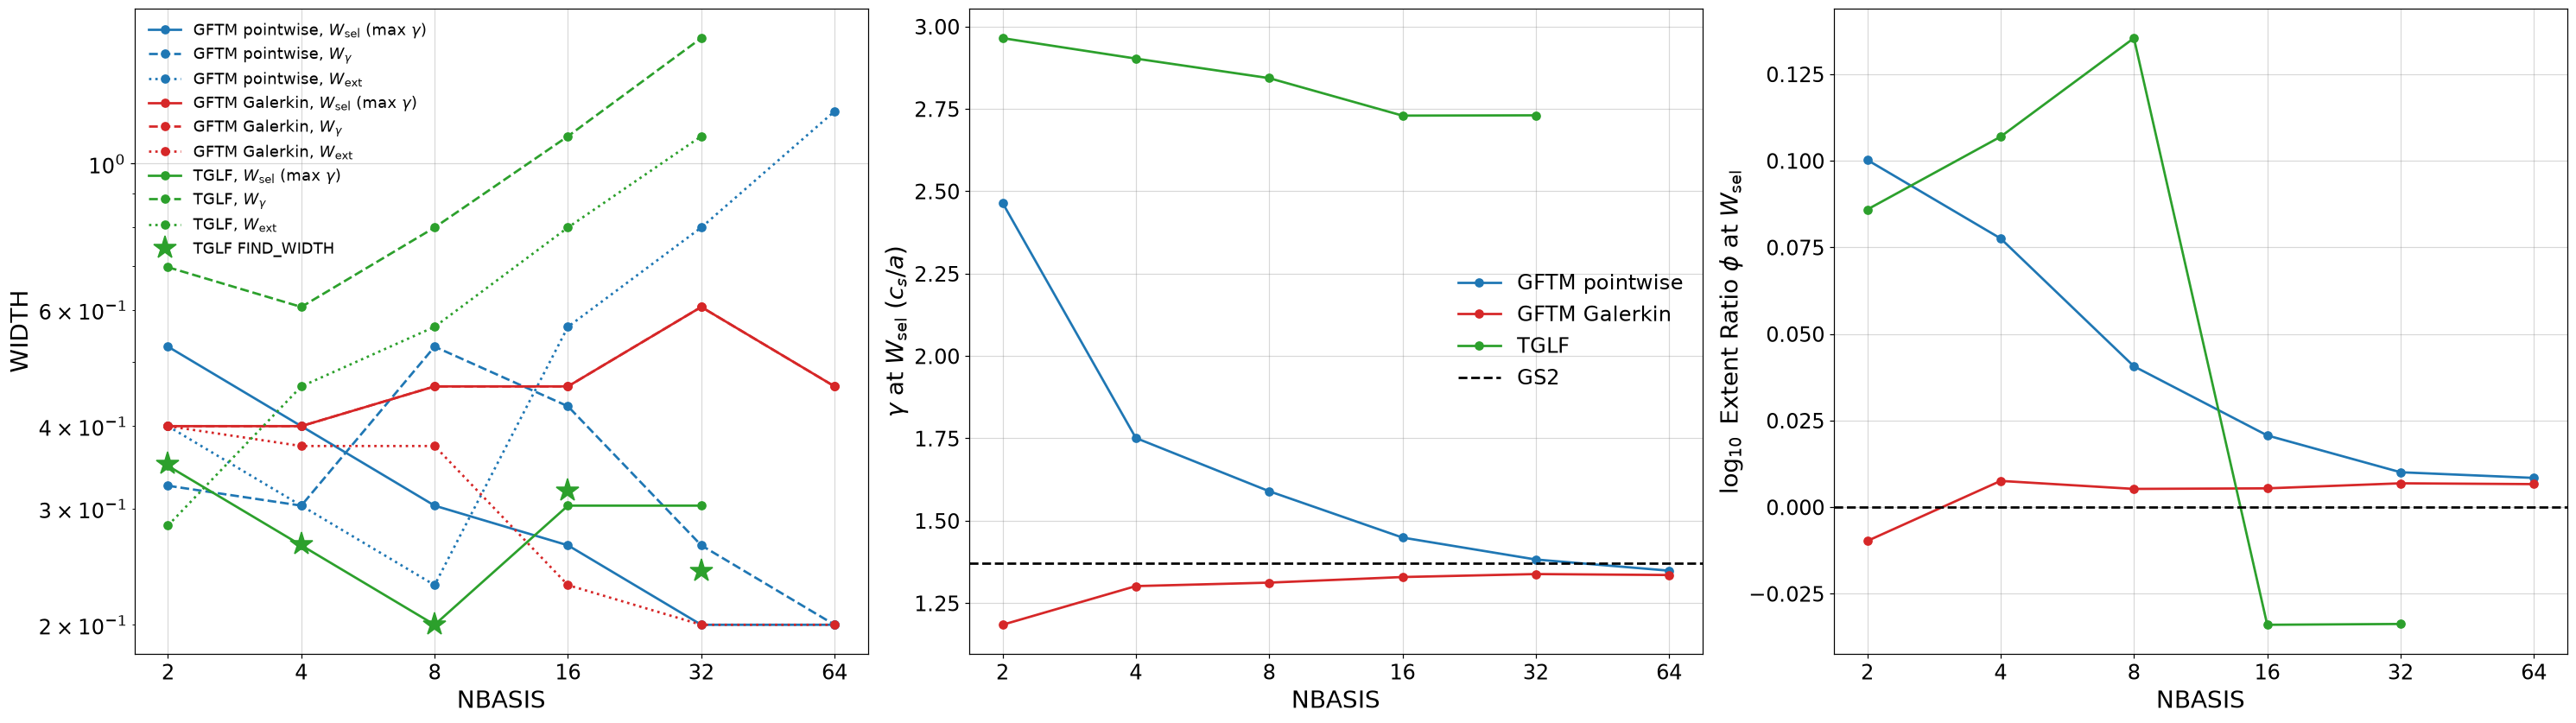

In [10]:
rows = []
for (arm, nb), a in table.groupby(["arm", "nb"]):
    a = a.reset_index(drop=True)
    pick = int(a.gamma.idxmax())
    rows.append(dict(arm=arm, nb=nb, w_sel=a.W[pick], w_gamma=a.W[(a.gamma - gamma_gs2).abs().idxmin()],
                     w_ext=a.W[a.log_extent_ratio_phi.abs().idxmin()], gamma_sel=a.gamma[pick], omega_sel=a.omega[pick],
                     log_extent_ratio_sel=a.log_extent_ratio_phi[pick]))
selection = pd.DataFrame(rows)
print(selection.round(4).to_string(index=False))

fig4, axes4 = plt.subplots(1, 3, figsize=(27, 7.5), squeeze=False)
for arm in arms:
    d = selection[selection.arm == arm].sort_values("nb")
    for column, ls, label in (("w_sel", "-", r"$W_{\rm sel}$ (max $\gamma$)"), ("w_gamma", "--", r"$W_\gamma$"), ("w_ext", ":", r"$W_{\rm ext}$")):
        axes4[0, 0].plot(d.nb, d[column], color=arm_colours[arm], ls=ls, marker="o", label=f"{arms[arm]}, {label}")
    axes4[0, 1].plot(d.nb, d.gamma_sel, color=arm_colours[arm], marker="o", label=arms[arm])
    axes4[0, 2].plot(d.nb, d.log_extent_ratio_sel, color=arm_colours[arm], marker="o", label=arms[arm])
axes4[0, 0].plot(find_width.nb_min, find_width.W, ls="", marker="*", ms=18, color=arm_colours["TGLF"], label="TGLF FIND_WIDTH")
axes4[0, 1].axhline(gamma_gs2, color="k", ls="--", marker="", label="GS2")
axes4[0, 2].axhline(0, color="k", ls="--", marker="", label="GS2")
for ax, ylabel in zip(axes4[0], ["WIDTH", r"$\gamma$ at $W_{\rm sel}$ ($c_s/a$)", r"$\log_{10}$ Extent Ratio $\phi$ at $W_{\rm sel}$"]):
    ax.set(xscale="log", xlabel="NBASIS", ylabel=ylabel)
    log_xticks(ax, nbasis_all)
axes4[0, 0].set_yscale("log")
axes4[0, 0].legend(fontsize=12, ncol=1)
axes4[0, 1].legend(fontsize=fs_legend)
plt.show()

## 5. Overshoot of the converged growth rate

$\gamma(W, N) / \gamma_{\rm conv}$ with $\gamma_{\rm conv} = \max_W \gamma(W, 64)$ of the same GFTM arm (qp5.24's "own NB64
max" reference); dotted line at $1 + 0.10$, the qp5.24 overshoot threshold. Above it, a max-$\gamma$ width search at
that $N$ picks a spurious width.

converged gamma (NB64 max over W): {'F': 1.3484, 'T': 1.3352} | GS2 1.3708


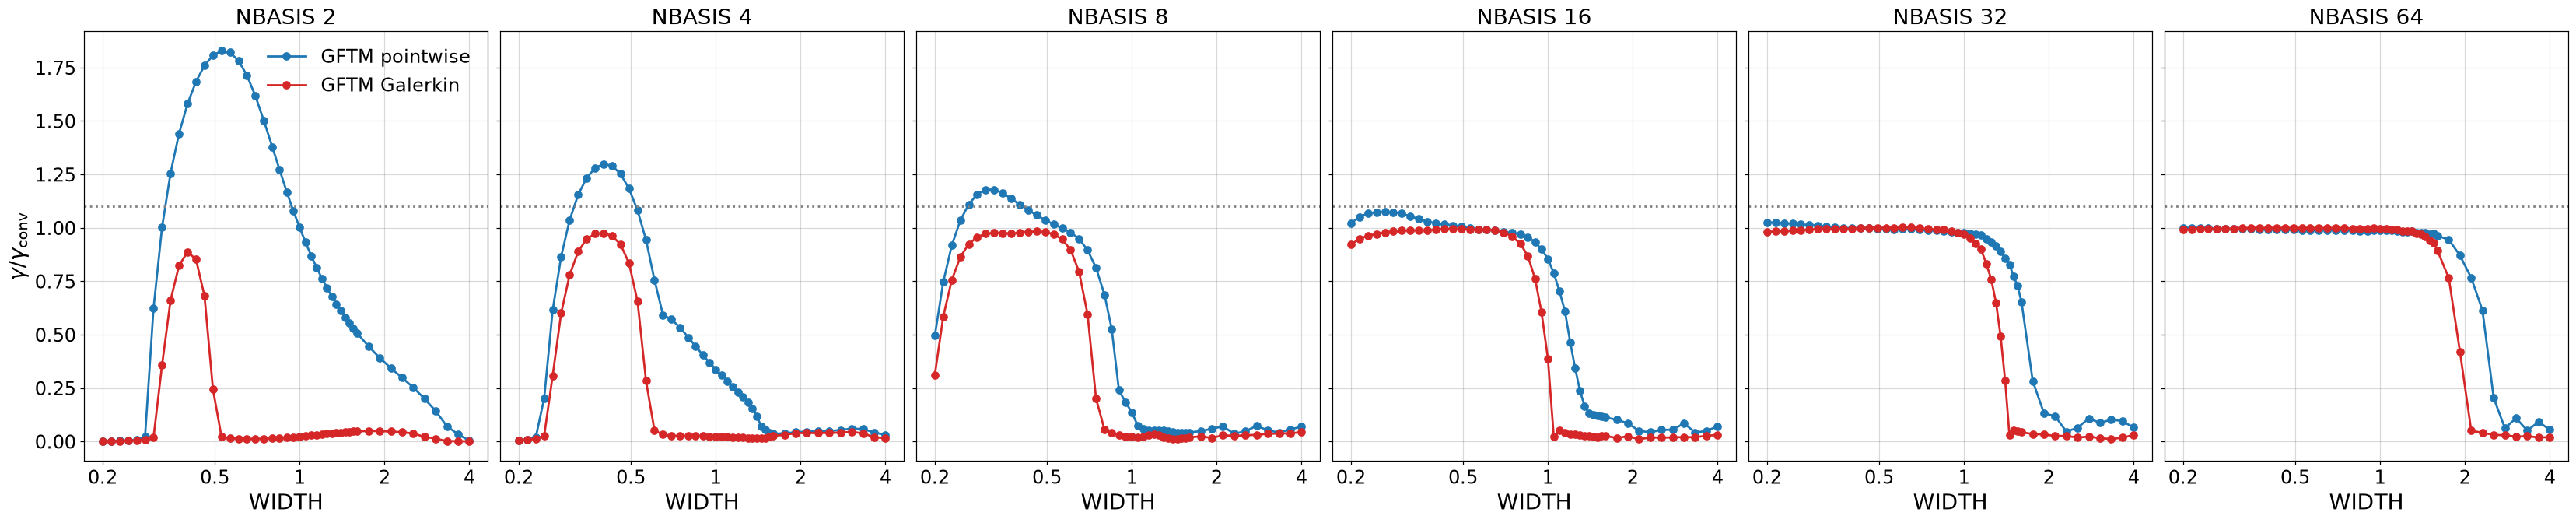

share of widths overshooting by >10%: nb      2      4      8    16   32   64
arm                                    
F    0.319  0.149  0.149  0.0  0.0  0.0
T    0.000  0.000  0.000  0.0  0.0  0.0


In [11]:
converged = table[table.nb == 64].groupby("arm").gamma.max()
table["gamma_over_converged"] = table.gamma / table.arm.map(converged)
print("converged gamma (NB64 max over W):", converged.round(4).to_dict(), "| GS2", round(gamma_gs2, 4))
gftm_only = table[table.arm.isin(["F", "T"])]
fig5, _ = per_nbasis(gftm_only, ["gamma_over_converged"], [r"$\gamma / \gamma_{\rm conv}$"], hline=1 + overshoot_tolerance, figsize=(30, 6))
plt.show()
print("share of widths overshooting by >10%:", gftm_only.assign(over=lambda t: t.gamma_over_converged > 1 + overshoot_tolerance)
      .groupby(["arm", "nb"]).over.mean().unstack().round(3).to_string())

In [12]:
out = ROOT / "Plots" / analysis_name
out.mkdir(parents=True, exist_ok=True)
for name, fig in (("fig0_case_gs2_eigenfunctions_and_parameters", fig0), ("fig1c_gamma_ratio_u_shape", fig1c), ("fig1d_omega_ratio_u_shape", fig1d), ("fig1e_self_convergence_vs_gaussian", fig1e), ("fig1_gamma_omega_vs_width_per_nbasis", fig1), ("fig2_eigenfunctions_phi", fig2), ("fig2b_eigenfunctions_apar", fig2b),
                  ("fig3_extent_ratio_vs_width_per_nbasis", fig3), ("fig4_width_selection_vs_nbasis", fig4),
                  ("fig5_overshoot_vs_width_per_nbasis", fig5)):
    fig.savefig(out / f"{name}.png", bbox_inches="tight")
selection.round(4).to_csv(out / "width_selection.csv", index=False)
parameters.round(5).to_csv(out / "sample_vs_base_parameters.csv")
print(sorted(p.name for p in out.iterdir()))

['fig0_case_gs2_eigenfunctions_and_parameters.png', 'fig1_gamma_omega_vs_width_per_nbasis.png', 'fig1c_gamma_ratio_u_shape.png', 'fig1d_omega_ratio_u_shape.png', 'fig1e_self_convergence_vs_gaussian.png', 'fig2_eigenfunctions_phi.png', 'fig2b_eigenfunctions_apar.png', 'fig3_extent_ratio_vs_width_per_nbasis.png', 'fig4_width_selection_vs_nbasis.png', 'fig5_overshoot_vs_width_per_nbasis.png', 'sample_vs_base_parameters.csv', 'width_selection.csv']


## v2 (Fusion_PhD-qp5.41, 2026-11-12): extent ratio against WIDTH per NBASIS under the qp5.37/qp5.40 settings

Section 3 again with two changes, both from the user: TGLF is run the qp5.37 way (SAT_RULE 2, FILTER $-1.5$, MHD rule off,
$A_\parallel$ and $B_\parallel$ on, fixed width, `NBASIS_MIN` = `NBASIS_MAX`), and every run has NXGRID $\ge$ NBASIS + 8 (qp5.40).
- TGLF `fixed_width_v2`: NBASIS 2/4/8/16/24 at NXGRID 32 (TGLF's maximum, so NBASIS 32 cannot comply; NXGRID 40 is reset to 16).
- GFTM stock (`galF`, FILTER 0.5): NBASIS 2/4/8/16 from the qp5.26 leaf (NXGRID 32), NBASIS 24 (NXGRID 32), 32 (NXGRID 40) and 56 (NXGRID 64) from `galF_v2`.
  The qp5.26 NBASIS 32 (NXGRID 32) and 64 (NXGRID 65) rows do not comply and are dropped by the NXGRID filter below.
- Settings of every run are per-sample variables of the cube; they are registered as `tglf_single_kbm_v2` / `gftm_single_kbm_v2` in `gftm_toolkit/settings/registry.py`.

In [ ]:
v2_leaves = {"F_old": (leaves["F"], bpar_leaves["F"]),
             "F": (single_root / "GFTM/Runs/single_mode_spr045/SPR-045/galF_v2_sample_0818", single_root / "GFTM/Runs/single_mode_spr045/SPR-045/bpar613/galF_v2_sample_0818"),
             "TGLF": (single_root / "TGLF/Runs/single_mode_spr045/SPR-045/fixed_width_v2_sample_0818", single_root / "TGLF/Runs/single_mode_spr045/SPR-045/bpar613/fixed_width_v2_sample_0818")}
rows_v2 = []
for arm, (leaf, bpar_leaf) in v2_leaves.items():
    scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    Extent(scan.gk_output, fraction=fraction)
    output = scan.gk_output.data.pint.dequantify().squeeze("ky", drop=True)
    bpar_scan = PyroHypercube(pyroscan_json=bpar_leaf / "pyroscan.json", load_base_pyro=True)
    bpar_scan.load_gk_output(netcdf_file=bpar_leaf / "pyroscan.nc")
    Extent(bpar_scan.gk_output, fraction=fraction)
    bpar_output = bpar_scan.gk_output.data.pint.dequantify().squeeze("ky", drop=True)
    dominant_index = output.growth_rate.fillna(-np.inf).argmax("mode")
    dominant = output.isel(mode=dominant_index)
    gamma = dominant.growth_rate.clip(min=0).fillna(0).values
    unstable = gamma > 0
    nxgrid = output.NXGRID.values.astype(int) if "NXGRID" in output else 32     # TGLF's NXGRID is a fixed code flag (32), not per-sample
    rows_v2.append(pd.DataFrame(dict(
        arm=arm.replace("_old", ""), W=np.round(output.WIDTH.values.astype(float), 4), nb=output.NBASIS_MAX.values.astype(int), nxgrid=nxgrid, gamma=gamma,
        **{f"extent_{field}": np.where(unstable, dominant.extent.sel(field=field).values, np.nan) for field in ["phi", "apar"]},
        extent_bpar=np.where(unstable, bpar_output.extent.sel(field="bpar").isel(mode=dominant_index).values, np.nan))))
table_v2 = pd.concat(rows_v2, ignore_index=True)
table_v2 = table_v2[table_v2.nxgrid >= table_v2.nb + 8].sort_values(["arm", "nb", "W"])     # the qp5.40 rule
for field in fields:
    table_v2[f"log_extent_ratio_{field}"] = np.log10(table_v2[f"extent_{field}"] / extent_gs2[field])
print(table_v2.groupby(["arm", "nb"]).agg(runs=("W", "size"), nxgrid=("nxgrid", "first")).T.to_string())
print("runs with no unstable mode:", table_v2[table_v2.gamma == 0].groupby(["arm", "nb"]).size().to_dict())
assert table_v2.groupby(["arm", "nb", "W"]).size().max() == 1, "a (code, NBASIS, WIDTH) cell is duplicated"

In [ ]:
nbasis_all = sorted(table_v2.nb.unique())      # per_nbasis reads this global: v2 columns are TGLF 2-24 and GFTM 2-56
fig3_v2, _ = per_nbasis(table_v2, [f"log_extent_ratio_{field}" for field in fields],
                        [rf"$\log_{{10}}$ Extent Ratio, {field_labels[field]}" for field in fields], hline=0, figsize=(30, 14))
plt.show()
fig3_v2.savefig(out / "fig3_extent_ratio_vs_width_per_nbasis_v2.png", bbox_inches="tight")